# 02 - Models, part 1: prepare, train, cross-validate

This notebook follows the class workflow (California housing example) after the EDA:

1. **Prepare the Data for Machine Learning Algorithms**: blanks, categorical attributes, scaling, pipelines
2. **Select and Train a Model**: baselines first, then LinearRegression, Ridge, and HistGradientBoosting
3. **Better Evaluation Using Cross-Validation**: one table with everything, plus feature importance

**No tuning and no test set scoring yet.** Those come in part 2. The test season (2025-26) is split off here and only its row count is printed.

Target: `PTS` (points in a game). Main metric: **MAE**, the average number of points the prediction is off by.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from build_features import FEATURES_V1 as FEATURES  # version 1's 33 features (version 2, at the end, adds 2)

FIG_DIR = ROOT / "figures"
RESULTS_DIR = ROOT / "results"
RESULTS_DIR.mkdir(exist_ok=True)

# chart style for the slides (same as the EDA notebook)
BLUE, ORANGE, INK, MUTED = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.dpi": 100, "savefig.dpi": 200, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#b5b4ae", "axes.labelcolor": INK, "axes.titleweight": "bold",
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "xtick.color": MUTED, "ytick.color": MUTED, "font.size": 11,
})
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 150)

df = pd.read_csv(ROOT / "data" / "processed" / "features.csv", parse_dates=["GAME_DATE"])
df = df[df["SEASON"] != "2026-27"]          # current season: live site only

# split by season, never randomly; sort by date because TimeSeriesSplit needs time order
train_set = (df[df["SEASON"].isin(["2023-24", "2024-25"])]
             .sort_values("GAME_DATE", kind="stable").reset_index(drop=True))
test_set = (df[df["SEASON"] == "2025-26"]
            .sort_values("GAME_DATE", kind="stable").reset_index(drop=True))

## Prepare the Data for Machine Learning Algorithms
1. Data Cleaning
2. Handling Text and Categorical Attributes
3. Feature Scaling
4. Transformation Pipelines

Same four steps as the class example. One difference: the class example does `X_train = train_set.drop("median_house_value", axis=1)`. We pick the `FEATURES` list instead, because our table also has ID columns (names, dates, teams) and `MIN`. `MIN` is how many minutes he actually played in that game, which you don't know before tip-off, so using it would be cheating.

In [2]:
X_train = train_set[FEATURES]
y_train = train_set["PTS"]
X_test = test_set[FEATURES]
y_test = test_set["PTS"]

print(f"train: {len(X_train):,} rows x {X_train.shape[1]} features "
      f"({train_set['GAME_DATE'].min().date()} to {train_set['GAME_DATE'].max().date()})")
print(f"test:  {len(X_test):,} rows (2025-26, locked away until the very end)")

train: 38,468 rows x 33 features (2023-10-24 to 2025-04-13)
test:  19,832 rows (2025-26, locked away until the very end)


### Cross-validation setup (used everywhere below)

The class example uses `cv=3`, which shuffles rows into folds. That doesn't work for us: it would train on March games and validate on November games, so the model would get to "see the future". **`TimeSeriesSplit(n_splits=5)`** always trains on earlier games and validates on the next block of later games, the same way the model will be used for real.

Every model and baseline gets scored on the same 5 validation blocks, so the numbers are directly comparable. Metrics: MAE (main), RMSE (punishes big misses more), R² (share of the game-to-game variation explained). We report the mean and the std across the 5 folds.

In [3]:
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error
from sklearn.model_selection import TimeSeriesSplit, cross_validate

tscv = TimeSeriesSplit(n_splits=5)

folds = []
for fold, (train_idx, val_idx) in enumerate(tscv.split(X_train), start=1):
    folds.append({"fold": fold, "train rows": len(train_idx),
                  "train through": train_set["GAME_DATE"].iloc[train_idx[-1]].date(),
                  "validate on": f"{train_set['GAME_DATE'].iloc[val_idx[0]].date()} to "
                                 f"{train_set['GAME_DATE'].iloc[val_idx[-1]].date()}",
                  "val rows": len(val_idx)})
display(pd.DataFrame(folds).set_index("fold"))

scoring = {"MAE": "neg_mean_absolute_error", "RMSE": "neg_root_mean_squared_error", "R2": "r2"}

def summarize(mae, rmse, r2):
    return {"MAE_mean": np.mean(mae), "MAE_std": np.std(mae),
            "RMSE_mean": np.mean(rmse), "RMSE_std": np.std(rmse),
            "R2_mean": np.mean(r2), "R2_std": np.std(r2)}

def cv_summary(model, X, y):
    """Cross-validate a pipeline with TimeSeriesSplit and return mean/std of each metric."""
    cv = cross_validate(model, X, y, cv=tscv, scoring=scoring)
    return summarize(-cv["test_MAE"], -cv["test_RMSE"], cv["test_R2"])

,train rows,train through,validate on,val rows
fold,,,,
1,6413,2023-12-21,2023-12-21 to 2024-02-14,6411
2,12824,2024-02-14,2024-02-14 to 2024-10-23,6411
3,19235,2024-10-23,2024-10-23 to 2024-12-21,6411
4,25646,2024-12-21,2024-12-21 to 2025-02-20,6411
5,32057,2025-02-20,2025-02-20 to 2025-04-13,6411


**Takeaway:** Each fold trains on everything up to a date and validates on the next ~6,400 games. Fold 1 only has about two months of 2023-24 to learn from, so it's the hardest. Fold 2's validation block spans the offseason (late 2023-24 plus opening week of 2024-25). By fold 5 the model has 32,000 games behind it. Averaging all 5 gives an honest "how does it do on games it hasn't seen yet" number.

### Data cleaning

Same idea as the class example's 3 options for the blank `total_bedrooms` values. Our blanks are `pts_prev_season` and `min_prev_season`: players with no NBA games last season (mostly rookies). We try the class example's 3 options plus a 4th:

1. **Drop those rows** (`dropna`)
2. **Drop those columns**
3. **Fill with the median** (`SimpleImputer(strategy="median")`)
4. **Median fill + a "was missing" flag** (`add_indicator=True`), so the model can treat rookies differently

There's also exactly one blank `ts_season` (a player who hadn't taken a shot yet), so every option keeps a median imputer in the pipeline to cover it. That way the only thing changing between options is how the rookie blanks are handled.

In [4]:
PREV_COLS = ["pts_prev_season", "min_prev_season"]

null_rows_idx = X_train.isnull().any(axis=1)
print(f"rows with any blank: {null_rows_idx.sum():,} of {len(X_train):,}")
print(X_train.isnull().sum()[lambda s: s > 0].to_string())
train_set.loc[null_rows_idx, ["PLAYER_NAME", "SEASON", "games_played", "pts_season"] + PREV_COLS].head()

rows with any blank: 3,473 of 38,468
ts_season             1
pts_prev_season    3472
min_prev_season    3472


,PLAYER_NAME,SEASON,games_played,pts_season,pts_prev_season,min_prev_season
277,Brandon Miller,2023-24,1,13.0,NaN,NaN
278,Ausar Thompson,2023-24,1,4.0,NaN,NaN
337,Chet Holmgren,2023-24,1,11.0,NaN,NaN
339,Cason Wallace,2023-24,1,13.0,NaN,NaN
371,Victor Wembanyama,2023-24,1,15.0,NaN,NaN


In [5]:
train_option1 = X_train.dropna(subset=PREV_COLS)           # option 1 (class used inplace=True, deprecated in pandas 3)
y_option1 = y_train.loc[train_option1.index]

train_option2 = X_train.drop(PREV_COLS, axis=1)             # option 2

# options 3 and 4 keep every row and column; the imputer inside the pipeline fills the blanks
print(f"option 1: {train_option1.shape}   option 2: {train_option2.shape}   options 3/4: {X_train.shape}")

option 1: (34996, 33)   option 2: (38468, 31)   options 3/4: (38468, 33)


In [6]:
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

def ridge_with(imputer):
    return make_pipeline(imputer, StandardScaler(), Ridge(alpha=1.0))

cleaning_results = pd.DataFrame({
    "option 1: drop the rows": cv_summary(ridge_with(SimpleImputer(strategy="median")),
                                          train_option1, y_option1),
    "option 2: drop the columns": cv_summary(ridge_with(SimpleImputer(strategy="median")),
                                             train_option2, y_train),
    "option 3: median fill": cv_summary(ridge_with(SimpleImputer(strategy="median")),
                                        X_train, y_train),
    "option 4: median fill + indicator": cv_summary(
        ridge_with(SimpleImputer(strategy="median", add_indicator=True)), X_train, y_train),
}).T
cleaning_results["rows scored"] = [len(train_option1), len(X_train), len(X_train), len(X_train)]
cleaning_results = cleaning_results.sort_values("MAE_mean")

winner = cleaning_results["MAE_mean"].idxmin()
print("winner by CV MAE:", winner)
cleaning_results.round(4)

winner by CV MAE: option 2: drop the columns


,MAE_mean,MAE_std,RMSE_mean,RMSE_std,R2_mean,R2_std,rows scored
option 2: drop the columns,4.9479,0.0571,6.3470,0.0732,0.4828,0.0142,38468
option 3: median fill,4.9486,0.0574,6.3477,0.0738,0.4827,0.0141,38468
option 4: median fill + indicator,4.9489,0.0573,6.3478,0.0736,0.4826,0.0141,38468
option 1: drop the rows,4.9935,0.0282,6.4030,0.0488,0.4867,0.0144,34996


**Takeaway:** Options 2, 3 and 4 are a dead tie: 4.948 vs 4.949 vs 4.949 MAE, a gap of 0.001 points when the fold-to-fold spread is 0.057. Following the rule (lowest CV MAE), **option 2 wins: drop `pts_prev_season` and `min_prev_season`**. That makes sense: last season's numbers are already built into `pts_blend`, `min_blend` and the opening-night fills, so the two raw columns add nothing new. Dropping them also means no rookie blanks to fill at all.

**Option 1 isn't a fair comparison.** It scores a different, smaller set of rows (34,996 instead of 38,468, no rookies), so its MAE isn't measuring the same thing. It also can't be used for real: the site would have no prediction for rookies.

### Handling Text and Categorical Attributes

The class example one-hot encodes `ocean_proximity` (text like "NEAR BAY"). **We have no categorical attributes.** Every feature is already a number. The yes/no ones (`HOME`, `back_to_back`, `starter_proxy`) are already stored as 0/1, which is exactly what one-hot encoding would produce. Player and team names are ID columns, not features, so there's nothing to encode and no `cat_pipeline`.

### Feature Scaling and Transformation Pipelines

Same as the class example: `num_pipeline = make_pipeline(SimpleImputer(...), StandardScaler())` wrapped in a `ColumnTransformer` called `preprocessing`. The imputer uses the data cleaning winner from above.

StandardScaler matters for Ridge, because its penalty treats all coefficients the same, so features need to be on the same scale (minutes are 0 to 48, `ts_hot` is about -0.4 to 0.4). Tree models like HistGB don't care about scale, but it doesn't hurt them either.

Because the imputer and scaler live **inside** the pipeline, cross-validation refits them on each fold's training part only. The median never "sees" the validation games.

In [7]:
from sklearn.compose import ColumnTransformer

# winner -> (columns to use, imputer settings). Option 1 isn't listed: dropping rows can't
# live inside a pipeline, and it would also mean the site can't predict for rookies.
CLEANING_CHOICES = {
    "option 2: drop the columns": ([f for f in FEATURES if f not in PREV_COLS],
                                   {"strategy": "median"}),
    "option 3: median fill": (FEATURES, {"strategy": "median"}),
    "option 4: median fill + indicator": (FEATURES, {"strategy": "median", "add_indicator": True}),
}
num_attribs, imputer_args = CLEANING_CHOICES[winner]

num_pipeline = make_pipeline(SimpleImputer(**imputer_args), StandardScaler())

preprocessing = ColumnTransformer([
    ("num", num_pipeline, num_attribs),
])

print(f"using {winner}: {len(num_attribs)} numeric attributes, imputer {imputer_args}")
preprocessing

using option 2: drop the columns: 31 numeric attributes, imputer {'strategy': 'median'}


,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. ``""{fe

## Select and Train a Model

### Baselines first (no fitting)

Before training anything, how good is "just guess his recent average"? These are the numbers every model has to beat. The proposal's baseline is `pts_l5` (last 5 games). We also try his season average and the blended average from the attribute-combinations notebook.

Baselines don't learn anything, but we still score them on **the same 5 validation blocks** as the models, so the comparison is fair.

In [8]:
def baseline_cv(col):
    """Score 'predict = this column' on the same TimeSeriesSplit validation folds."""
    mae, rmse, r2 = [], [], []
    for _, val_idx in tscv.split(X_train):
        y_true, y_pred = y_train.iloc[val_idx], X_train[col].iloc[val_idx]
        mae.append(mean_absolute_error(y_true, y_pred))
        rmse.append(root_mean_squared_error(y_true, y_pred))
        r2.append(r2_score(y_true, y_pred))
    return summarize(mae, rmse, r2)

results = {}
for col in ["pts_l5", "pts_season", "pts_blend"]:
    results[f"baseline: {col}"] = {"type": "baseline", **baseline_cv(col)}

pd.DataFrame(results).T.drop(columns="type").astype(float).round(3)

,MAE_mean,MAE_std,RMSE_mean,RMSE_std,R2_mean,R2_std
baseline: pts_l5,5.274,0.020,6.812,0.038,0.404,0.024
baseline: pts_season,5.091,0.049,6.567,0.062,0.446,0.029
baseline: pts_blend,5.078,0.062,6.549,0.092,0.449,0.030


**Takeaway:** "Last 5 games" (`pts_l5`, the proposal's baseline) is the weakest guess: off by **5.27 points** on average. Longer averages do better: season average 5.09, blended average 5.08. Five games is a small sample, so one 40-point night or one foul-trouble night swings it a lot. Every model below has to beat 5.27, and really should beat 5.08.

### LinearRegression (the class example's model)

Same steps as the class example: build `make_pipeline(preprocessing, LinearRegression())`, fit on the whole training set, compare a few predictions with the real values, and measure the error **on the training set itself**. Training error alone doesn't tell you much, but comparing it with the cross-validation error does:

- training error much lower than CV error = **overfitting** (memorized the training games)
- both about the same and both high = **underfitting** (model too simple)

In [9]:
from sklearn.linear_model import LinearRegression

lin_reg = make_pipeline(preprocessing, LinearRegression())
lin_reg.fit(X_train, y_train)

train_predictions = lin_reg.predict(X_train)
print("predicted:", train_predictions[:5].round(1))
print("actual:   ", y_train.iloc[:5].values)

predicted: [27.1  9.8 23.5 10.  15.1]
actual:    [21  8 17 20 15]


In [10]:
lin_mae = mean_absolute_error(y_train, train_predictions)
lin_rmse = root_mean_squared_error(y_train, train_predictions)
print(f"LinearRegression training set:  MAE {lin_mae:.3f}  RMSE {lin_rmse:.3f}")

results["LinearRegression"] = {"type": "model", **cv_summary(lin_reg, X_train, y_train),
                               "train_MAE": lin_mae, "train_RMSE": lin_rmse}
print("LinearRegression cross-validation: "
      f"MAE {results['LinearRegression']['MAE_mean']:.3f} (+/- {results['LinearRegression']['MAE_std']:.3f})")

LinearRegression training set:  MAE 4.904  RMSE 6.300


LinearRegression cross-validation: MAE 4.948 (+/- 0.057)


### Ridge and HistGradientBoosting

Same steps for the two models from the proposal:
- **Ridge(alpha=1.0)**: linear regression with a small penalty on big coefficients. Helps when features overlap a lot (we have pts_season, pts_l10 and pts_blend, which mostly say the same thing).
- **HistGradientBoostingRegressor(random_state=42)**: builds a few hundred small decision trees, each fixing the previous ones' mistakes. Unlike a linear model, it can pick up curves and interactions (like "teammates out matters more for starters").

Default settings for both. Tuning is part 2.

In [11]:
from sklearn.ensemble import HistGradientBoostingRegressor

def train_and_cv(name, model):
    model.fit(X_train, y_train)
    pred = model.predict(X_train)
    train_mae = mean_absolute_error(y_train, pred)
    train_rmse = root_mean_squared_error(y_train, pred)
    results[name] = {"type": "model", **cv_summary(model, X_train, y_train),
                     "train_MAE": train_mae, "train_RMSE": train_rmse}
    r = results[name]
    print(f"{name}")
    print(f"  training set:     MAE {train_mae:.3f}  RMSE {train_rmse:.3f}")
    print(f"  cross-validation: MAE {r['MAE_mean']:.3f} (+/- {r['MAE_std']:.3f})  "
          f"RMSE {r['RMSE_mean']:.3f}  R2 {r['R2_mean']:.3f}")

ridge_reg = make_pipeline(preprocessing, Ridge(alpha=1.0))
train_and_cv("Ridge", ridge_reg)

hgb_reg = make_pipeline(preprocessing, HistGradientBoostingRegressor(random_state=42))
train_and_cv("HistGradientBoosting", hgb_reg)

Ridge
  training set:     MAE 4.904  RMSE 6.300
  cross-validation: MAE 4.948 (+/- 0.057)  RMSE 6.347  R2 0.483


HistGradientBoosting
  training set:     MAE 4.677  RMSE 5.979
  cross-validation: MAE 4.993 (+/- 0.050)  RMSE 6.409  R2 0.473


**Takeaway:**
- **LinearRegression and Ridge are identical** (4.948 CV MAE). With 38,000 rows, `alpha=1.0` is too small a penalty to change anything. Tuning alpha in part 2 will show whether a stronger penalty helps.
- **The linear models aren't overfitting.** Training MAE 4.90 vs CV MAE 4.95 is a tiny gap. Their limit is information, not memorization: a lot of game-to-game scoring is just randomness the features can't see (hot nights, foul trouble, blowouts).
- **HistGB overfits a bit and loses to Ridge for now.** Training MAE 4.68 vs CV MAE 4.99: it learned some patterns from the training games that don't carry over to new ones. Default settings let its trees chase noise. Part 2 tunes `min_samples_leaf`, `max_depth` and `learning_rate`, which is exactly what controls that.

## Better Evaluation Using Cross-Validation

The class example (and the textbook) moves to cross-validation once the training error turns out to be misleading. We've been using CV all along, so this section puts everything side by side in one table: every baseline and every model, scored on the same 5 time-ordered validation blocks, sorted by CV MAE (lower is better).

`train_MAE` is only there for the models (baselines don't train).

In [12]:
cv_results = pd.DataFrame(results).T
num_cols = [c for c in cv_results.columns if c != "type"]
cv_results[num_cols] = cv_results[num_cols].astype(float)
cv_results = cv_results.sort_values("MAE_mean")
cv_results.index.name = "approach"

best_baseline = cv_results.loc[cv_results["type"] == "baseline", "MAE_mean"].min()
cv_results["MAE_vs_best_baseline"] = cv_results["MAE_mean"] - best_baseline
cv_results["MAE_vs_pts_l5"] = cv_results["MAE_mean"] - cv_results.loc["baseline: pts_l5", "MAE_mean"]

cv_results.to_csv(RESULTS_DIR / "cv_results_part1.csv")
show = ["type", "MAE_mean", "MAE_std", "RMSE_mean", "RMSE_std", "R2_mean", "R2_std",
        "train_MAE", "MAE_vs_pts_l5"]
cv_results[show].round(3)

,type,MAE_mean,MAE_std,RMSE_mean,RMSE_std,R2_mean,R2_std,train_MAE,MAE_vs_pts_l5
approach,,,,,,,,,
Ridge,model,4.948,0.057,6.347,0.073,0.483,0.014,4.904,-0.326
LinearRegression,model,4.948,0.057,6.347,0.073,0.483,0.014,4.904,-0.326
HistGradientBoosting,model,4.993,0.050,6.409,0.081,0.473,0.013,4.677,-0.281
baseline: pts_blend,baseline,5.078,0.062,6.549,0.092,0.449,0.030,NaN,-0.196
baseline: pts_season,baseline,5.091,0.049,6.567,0.062,0.446,0.029,NaN,-0.183
baseline: pts_l5,baseline,5.274,0.020,6.812,0.038,0.404,0.024,NaN,0.000


**Takeaway:**
- **Every model beats every baseline.** Ridge is off by 4.95 points per game vs 5.27 for the last-5 baseline: **0.33 points better, about 6%**. Against the best baseline (`pts_blend`, 5.08) the gain is 0.13 points.
- **R² goes from 0.40 (last-5 baseline) to 0.48 (Ridge).** The model explains about half of the game-to-game variation in points. The other half is the stuff nobody can see before tip-off.
- **Ridge vs HistGB (0.045 points) is smaller than the fold-to-fold spread (~0.05).** It's too early to call a winner between them. Tuning in part 2 decides.
- 6% doesn't sound like much, but the baseline is already "his own recent scoring", which is hard to beat. NBA scoring is noisy: even a perfect model can't know about a random 40-point night.

### Which features does HistGB actually use? (permutation importance)

**Permutation importance:** take the trained model, shuffle one feature's column so it becomes random noise, and see how much worse the predictions get. If MAE jumps, the model relied on that feature. If nothing changes, it ignored it.

We fit HistGB on the **last CV fold's** training part (all games through Feb 20, 2025) and measure on that fold's validation games (the rest of 2024-25). Those are games the model never saw, so this shows what helps on new games, not what it memorized. Each feature is shuffled 10 times and averaged.

In [13]:
from sklearn.base import clone
from sklearn.inspection import permutation_importance

train_idx, val_idx = list(tscv.split(X_train))[-1]
hgb_last_fold = clone(hgb_reg).fit(X_train.iloc[train_idx], y_train.iloc[train_idx])

X_val = X_train.iloc[val_idx][num_attribs]
y_val = y_train.iloc[val_idx]
perm = permutation_importance(hgb_last_fold, X_val, y_val, scoring="neg_mean_absolute_error",
                              n_repeats=10, random_state=42)

importance = (pd.DataFrame({"MAE_increase": perm.importances_mean, "std": perm.importances_std},
                           index=num_attribs)
              .sort_values("MAE_increase", ascending=False))
importance.round(4)

,MAE_increase,std
pts_blend,1.2779,0.0329
tsa_l5,0.2024,0.0088
team_missing_min,0.1298,0.0080
pts_l10,0.0778,0.0063
pts_l3,0.0411,0.0053
min_l3,0.0279,0.0065
tsa_season,0.0168,0.0041
net_rtg_gap,0.0126,0.0037
pts_season,0.0122,0.0014
games_missed,0.0083,0.0021


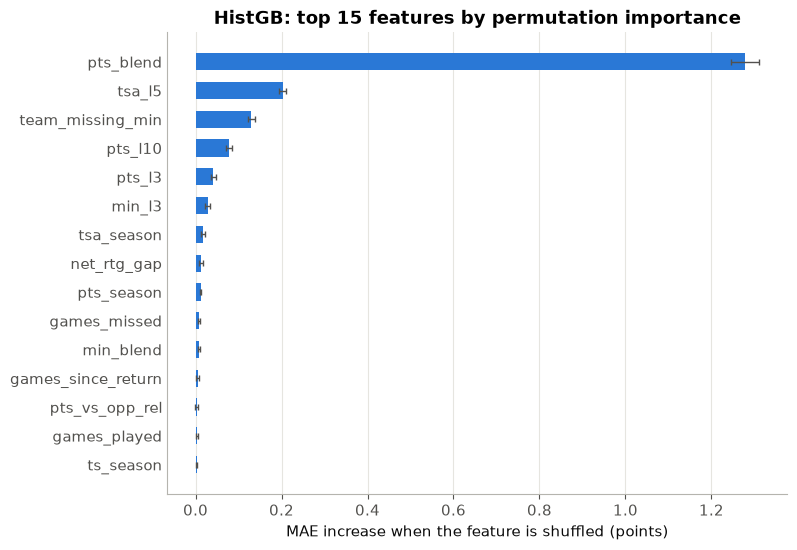

In [14]:
top = importance.head(15).iloc[::-1]   # biggest at the top of the chart

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(top.index, top["MAE_increase"], xerr=top["std"], color=BLUE, height=0.6,
        error_kw={"ecolor": MUTED, "elinewidth": 1, "capsize": 2})
ax.set_xlabel("MAE increase when the feature is shuffled (points)")
ax.set_title("HistGB: top 15 features by permutation importance")
ax.grid(axis="y", visible=False)
ax.tick_params(axis="y", length=0)
fig.savefig(FIG_DIR / "09_hgb_permutation_importance.png")
plt.show()

**Takeaway:**
- **`pts_blend` dominates.** Shuffling it makes HistGB 1.28 points worse per game. "How much does he usually score" is the backbone of every prediction.
- **Next: `tsa_l5` (0.20), recent shot volume, and `team_missing_min` (0.13), teammates out tonight.** That's the usage effect from the attribute-combinations notebook showing up in a real model, and it backs the site's "who's out tonight" toggle.
- **Then recent form (`pts_l10`, `pts_l3`, `min_l3`).** Opponent defense, pace, home/away, rest and matchup history are all near 0.
- **Careful reading this:** features that say the same thing share the credit. `pts_season` and `pts_l5` look useless here only because when one is shuffled, `pts_blend` covers for it. Near-zero means "nothing new beyond the other features", not "unrelated to points". A few small negatives (like `opp_missing_min`) are just noise.

## Key findings (part 1)

- **All 3 models beat the "last 5 games" baseline.** Ridge is off by 4.95 points per game vs 5.27, about 6% better, and explains about half the game-to-game variation (R² 0.48 vs 0.40).
- **Simple wins for now.** Untuned, Ridge (4.95) edges HistGB (4.99), and HistGB shows mild overfitting (training MAE 4.68). The gap is within fold-to-fold noise, so tuning in part 2 decides.
- **Longer averages beat short ones.** As baselines, the season and blended averages (5.08 to 5.09) beat last-5 (5.27). Five games is too noisy a sample.
- **Last season's numbers are already built into the blend**, so the raw prev-season columns added nothing and were dropped (the data cleaning options tied within 0.001 points).
- **What the model uses:** his blended scoring average by far, then recent shot volume and teammates being out tonight. Opponent and schedule features barely move it.

---
# Part 2a: Fine-Tune Your Model

Class workflow step **"Fine-Tune Your Model"**: the class example uses `GridSearchCV` (try every combination in a small grid) and `RandomizedSearchCV` (try N random combinations from wider ranges), then looks at `best_params_`. We do the same for Ridge, a new linear model (Huber), and HistGB.

Before running the official searches here, a wider exploratory search (~480 configurations: feature sets, training windows, losses, splines, recency weighting, two-stage) was run separately. Its scripts and raw results are in `results/search/`. This part builds the winners from that search properly, with the class tools.

**Still no test set.** Everything is scored on cross-validation folds inside 2023-24 and 2024-25.

## Step 0: date-safe folds and how much history to train on

Two changes from part 1:

1. **Train on more seasons.** Part 1 only trained on 2023-24 and 2024-25. Now the training data can reach back to 2018-19, and we test whether that helps.
2. **Date-safe folds.** `TimeSeriesSplit` cuts at a row count, so a cut can land in the middle of a game night: some games from Jan 5 in training, others from Jan 5 in validation. Our features only use earlier games, so that isn't leakage, but it's cleaner to snap every boundary to a date change. No date ever appears in both training and validation.

The folds keep the TimeSeriesSplit pattern: 2023-24 + 2024-25 are cut into 6 equal chunks. The first chunk is training-only, and each of the other 5 is a validation block. **Each fold trains on every row (back to the window start) dated before its block.** We build the folds as a list of `(train_idx, val_idx)` and pass that list as `cv=` everywhere, which sklearn accepts the same way as `cv=3`.

In [15]:
from joblib import Parallel, delayed
from sklearn.linear_model import HuberRegressor

EVAL_SEASONS = ["2023-24", "2024-25"]
full = df[df["SEASON"] <= "2024-25"].sort_values("GAME_DATE", kind="stable")   # never 2025-26

def date_safe_starts(dates, n_splits):
    """TimeSeriesSplit-style block start dates. Blocks are defined by date, so a boundary
    can never split one game night between training and validation."""
    dates = dates.sort_values().reset_index(drop=True)
    size = len(dates) // (n_splits + 1)
    return [dates.iloc[k * size].to_datetime64() for k in range(1, n_splits + 1)]

eval_dates = full.loc[full["SEASON"].isin(EVAL_SEASONS), "GAME_DATE"]
VAL_STARTS = date_safe_starts(eval_dates, 5)
VAL_BOUNDS = VAL_STARTS + [(eval_dates.max() + pd.Timedelta(days=1)).to_datetime64()]

def make_folds(frame):
    """List of (train_idx, val_idx) positions in `frame` (which must be sorted by date)."""
    dates = frame["GAME_DATE"].to_numpy()
    is_eval = frame["SEASON"].isin(EVAL_SEASONS).to_numpy()
    folds = []
    for start, end in zip(VAL_BOUNDS[:-1], VAL_BOUNDS[1:]):
        train_idx = np.where(dates < start)[0]
        val_idx = np.where(is_eval & (dates >= start) & (dates < end))[0]
        folds.append((train_idx, val_idx))
    return folds

def window(first_season):
    """Training data from `first_season` through 2024-25, sorted by date."""
    return full[full["SEASON"] >= first_season].reset_index(drop=True)

frame7 = window("2018-19")
folds7 = make_folds(frame7)
rows = []
for k, (tr, va) in enumerate(folds7, start=1):
    tr_dates, va_dates = frame7["GAME_DATE"].iloc[tr], frame7["GAME_DATE"].iloc[va]
    assert tr_dates.max() < va_dates.min()          # no date in both train and validation
    rows.append({"fold": k, "train rows": len(tr), "train from": tr_dates.min().date(),
                 "train through": tr_dates.max().date(), "validate on": f"{va_dates.min().date()} to "
                 f"{va_dates.max().date()}", "val rows": len(va)})
pd.DataFrame(rows).set_index("fold")

,train rows,train from,train through,validate on,val rows
fold,,,,,
1,99753,2018-10-16,2023-12-20,2023-12-21 to 2024-02-13,6378
2,106131,2018-10-16,2024-02-13,2024-02-14 to 2024-10-22,6371
3,112502,2018-10-16,2024-10-22,2024-10-23 to 2024-12-20,6333
4,118835,2018-10-16,2024-12-20,2024-12-21 to 2025-02-19,6586
5,125421,2018-10-16,2025-02-19,2025-02-20 to 2025-04-13,6415


**Takeaway:** Every fold now trains on 100,000 to 125,000 games going back to October 2018 (part 1: 6,000 to 32,000). The validation blocks are about 6,400 games each, and the check passed: no date is in both training and validation. Fold 2 still spans the offseason (late 2023-24 plus opening week of 2024-25).

### Training window: 3, 5 or 8 seasons of data

The proposal promised comparing 3, 5 and 8 seasons of data in total, counting the 2025-26 test season. So training starts in 2023-24 (3 total), 2021-22 (5 total) or 2018-19 (8 total). The 8-season version includes the two odd COVID seasons (2019-20 bubble, 2020-21 with empty arenas).

We score the same model, Huber with default settings (explained in Step 2), on **the exact same validation games** for each window. Only the amount of training history changes. The preprocessing is the one explained in Step 1.

In [16]:
from sklearn.pipeline import Pipeline

# explained in Step 1: median fill + "was missing" flag, then scaling
preprocessing = ColumnTransformer([
    ("num", make_pipeline(SimpleImputer(strategy="median", add_indicator=True), StandardScaler()),
     FEATURES),
])

def huber_default():
    return Pipeline([("preprocessing", preprocessing), ("huber", HuberRegressor(max_iter=1000))])

WINDOWS = {"3 seasons (train from 2023-24)": "2023-24",
           "5 seasons (train from 2021-22)": "2021-22",
           "8 seasons (train from 2018-19)": "2018-19"}
window_rows = {}
for label, first in WINDOWS.items():
    frame = window(first)
    folds = make_folds(frame)
    cv = cross_validate(huber_default(), frame[FEATURES], frame["PTS"], cv=folds,
                        scoring=scoring, n_jobs=-1)
    window_rows[label] = {"train rows (last fold)": len(folds[-1][0]),
                          **summarize(-cv["test_MAE"], -cv["test_RMSE"], cv["test_R2"]),
                          **{f"fold{k}": m for k, m in enumerate(-cv["test_MAE"], start=1)}}
window_results = pd.DataFrame(window_rows).T

# Decision rule (same one Step 5 uses): the plan is 8 seasons. A smaller window
# replaces it only if it has a lower MAE in at least 4 of the 5 folds.
PLAN = "8 seasons (train from 2018-19)"
fold_cols = [f"fold{k}" for k in range(1, 6)]
window_results["folds beating 8 seasons"] = [
    int((window_results.loc[w, fold_cols] < window_results.loc[PLAN, fold_cols]).sum())
    for w in window_results.index]
challengers = window_results.drop(PLAN)
challengers = challengers[challengers["folds beating 8 seasons"] >= 4]
best_window = challengers["MAE_mean"].idxmin() if len(challengers) else PLAN
FIRST_SEASON = WINDOWS[best_window]
print("lowest mean MAE:", window_results["MAE_mean"].idxmin())
print("chosen (4-of-5 rule):", best_window)
window_results.round(4)

lowest mean MAE: 5 seasons (train from 2021-22)
chosen (4-of-5 rule): 8 seasons (train from 2018-19)


,train rows (last fold),MAE_mean,MAE_std,RMSE_mean,RMSE_std,R2_mean,R2_std,fold1,fold2,fold3,fold4,fold5,folds beating 8 seasons
3 seasons (train from 2023-24),32053.0,4.9255,0.0394,6.3540,0.0572,0.4814,0.0167,4.9886,4.9406,4.9307,4.8782,4.8894,2
5 seasons (train from 2021-22),70637.0,4.9124,0.0243,6.3329,0.0437,0.4848,0.0175,4.9283,4.9367,4.9315,4.8814,4.8843,3
8 seasons (train from 2018-19),125421.0,4.9126,0.0235,6.3313,0.0441,0.4850,0.0176,4.9266,4.9350,4.9331,4.8821,4.8861,0


**Takeaway:**
- **3 seasons is clearly worst** (4.926). Almost all of that is fold 1, where it has only two months of 2023-24 to learn from (4.989 vs 4.927 with more history).
- **5 vs 8 seasons is a tie:** 4.9124 vs 4.9126, a 0.0002 gap. 5 seasons wins 3 folds and 8 seasons wins 2. Under the 4-of-5 rule, no smaller window beats the plan, so **we train on 8 seasons total (2018-19 to 2024-25, plus 2025-26 as the test)**.
- Two things point the same way: with the tuned Huber settings, 8 seasons came out slightly ahead in the search (4.9361 vs 4.9369, `results/search/`), and the top 7 HistGB configurations in the search all used 8 seasons.
- **The COVID seasons didn't hurt.** Adding 2018-19 through 2020-21 (bubble, empty arenas) left the score unchanged.
- Slide version: more history helps a lot at first, then levels off around 5 seasons.

## Step 1: preprocessing

Same `ColumnTransformer` as part 1, with one change: **we keep `pts_prev_season` and `min_prev_season`** and use `SimpleImputer(strategy="median", add_indicator=True)`. The indicator adds a 0/1 "this value was blank" column, so the model can treat rookies (no last season) differently instead of pretending they had a median season.

In part 1 (2 seasons of training), dropping those columns won by 0.001 points, a tie. With 7 seasons of training it's still basically a tie, as the check below shows. We keep the columns plus the indicator: it matched or beat dropping them in the wider search too, and it keeps the information available for HistGB, which can use it in non-linear ways.

In [17]:
train_frame = window(FIRST_SEASON)  # from here on: the chosen training window
train_folds = make_folds(train_frame)
X_train = train_frame[FEATURES]
y_train = train_frame["PTS"]
folds = train_folds
print(f"training on {FIRST_SEASON} to 2024-25: {len(X_train):,} rows")

PREV_COLS = ["pts_prev_season", "min_prev_season"]
drop_pre = ColumnTransformer([
    ("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()),
     [f for f in FEATURES if f not in PREV_COLS]),
])
check = {}
for label, pre in [("drop the columns (part 1 winner)", drop_pre),
                   ("median fill + indicator", preprocessing)]:
    cv = cross_validate(Pipeline([("preprocessing", pre), ("huber", HuberRegressor(max_iter=1000))]),
                        X_train, y_train, cv=folds, scoring=scoring, n_jobs=-1)
    check[label] = summarize(-cv["test_MAE"], -cv["test_RMSE"], cv["test_R2"])
pd.DataFrame(check).T.round(4)

training on 2018-19 to 2024-25: 131,836 rows


,MAE_mean,MAE_std,RMSE_mean,RMSE_std,R2_mean,R2_std
drop the columns (part 1 winner),4.9124,0.0240,6.3312,0.0445,0.4851,0.0176
median fill + indicator,4.9126,0.0235,6.3313,0.0441,0.4850,0.0176


**Takeaway:** Another tie: 4.9124 (drop the columns) vs 4.9126 (keep them + indicator), 0.0002 apart. So keeping the columns with an indicator matches dropping them, and the wider search had it 0.0001 ahead (4.9361 vs 4.9362). We keep them: same score, and HistGB gets one more piece of information (rookie or not) it can use in non-linear ways.

## Step 2: Fine-Tune Your Model

Same tools as the class example, with two changes: `cv=folds` (our date-safe folds instead of `cv=3`) and `scoring="neg_mean_absolute_error"` (MAE is our main metric; the class example used RMSE). sklearn always maximizes the score, so MAE comes out negative and we flip the sign.

Three models:
- **Ridge**, `GridSearchCV` over `alpha` (penalty strength).
- **HuberRegressor**, `GridSearchCV` over `epsilon` and `alpha`. A linear regression that **doesn't let rare 40-point nights pull its predictions up**. Ordinary least squares squares every error, so one huge miss counts like 100 small ones. Huber squares small errors but only counts big ones linearly, past `epsilon` standard deviations, which is much closer to how MAE grades. Lower `epsilon` = more resistant to outliers.
- **HistGradientBoosting**, `RandomizedSearchCV` with 30 random combinations. Each combination is trained 5 times (once per fold), so this is the slow one.

In [18]:
from scipy.stats import loguniform
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV

def search_report(search, name):
    """best_params_, best CV MAE, training MAE (overfitting check), and the top 5 rows."""
    train_mae = mean_absolute_error(y_train, search.best_estimator_.predict(X_train))
    print(f"{name} best params: {search.best_params_}")
    print(f"  best CV MAE {-search.best_score_:.4f}  |  training MAE {train_mae:.4f}")
    top = pd.DataFrame(search.cv_results_).sort_values("rank_test_score").head(5)
    top = top[["params", "mean_test_score", "std_test_score"]].assign(
        mean_test_score=lambda t: -t["mean_test_score"])
    return train_mae, top.rename(columns={"mean_test_score": "CV MAE", "std_test_score": "std"})

ridge_pipeline = Pipeline([("preprocessing", preprocessing), ("ridge", Ridge())])
param_grid = [{"ridge__alpha": [0.1, 1, 10, 100, 1000]}]
ridge_search = GridSearchCV(ridge_pipeline, param_grid, cv=folds,
                            scoring="neg_mean_absolute_error", n_jobs=-1)
ridge_search.fit(X_train, y_train)
ridge_train_mae, top = search_report(ridge_search, "Ridge")
top

Ridge best params: {'ridge__alpha': 0.1}
  best CV MAE 4.9372  |  training MAE 4.8535


,params,CV MAE,std
0,{'ridge__alpha': 0.1},4.937183,0.024412
1,{'ridge__alpha': 1},4.937186,0.024414
2,{'ridge__alpha': 10},4.937214,0.024434
3,{'ridge__alpha': 100},4.937554,0.024654
4,{'ridge__alpha': 1000},4.940828,0.025972


In [19]:
huber_pipeline = Pipeline([("preprocessing", preprocessing),
                           ("huber", HuberRegressor(max_iter=1000))])
param_grid = [{"huber__epsilon": [1.1, 1.35, 1.6], "huber__alpha": [1e-4, 1e-3, 1e-2]}]
huber_search = GridSearchCV(huber_pipeline, param_grid, cv=folds,
                            scoring="neg_mean_absolute_error", n_jobs=-1)
huber_search.fit(X_train, y_train)
huber_train_mae, top = search_report(huber_search, "Huber")
top

Huber best params: {'huber__alpha': 0.001, 'huber__epsilon': 1.1}
  best CV MAE 4.9087  |  training MAE 4.8334


,params,CV MAE,std
3,"{'huber__alpha': 0.001, 'huber__epsilon': 1.1}",4.908664,0.023497
6,"{'huber__alpha': 0.01, 'huber__epsilon': 1.1}",4.908675,0.023526
0,"{'huber__alpha': 0.0001, 'huber__epsilon': 1.1}",4.908688,0.023514
1,"{'huber__alpha': 0.0001, 'huber__epsilon': 1.35}",4.912594,0.023467
4,"{'huber__alpha': 0.001, 'huber__epsilon': 1.35}",4.912596,0.023460


**Takeaway:**
- **Ridge: alpha doesn't matter.** 0.1 through 100 are within 0.0004 of each other. With 130,000 rows the penalty barely changes anything, so tuned Ridge is the same model as LinearRegression.
- **Huber: `epsilon = 1.1` wins**, the most outlier-resistant value we tried. `alpha` doesn't matter.
- **Huber beats Ridge by 0.03 points per game (4.909 vs 4.937)** with the same features, just by changing how errors are counted. Rare huge nights stop dragging every prediction up.
- **No overfitting:** training MAE 4.83 vs CV MAE 4.91 for Huber, 4.85 vs 4.94 for Ridge. Part of that gap is just that CV folds are later in time with less training data.

### HistGradientBoosting: RandomizedSearchCV

What each setting does:
- `loss`: `absolute_error` aims straight at MAE (predicts the typical night, the median), `squared_error` aims at the average (which big nights pull up)
- `learning_rate` and `max_iter`: how big each correction step is, and how many trees. Small steps with many trees is slower but steadier.
- `max_leaf_nodes`: how complex each tree can be
- `min_samples_leaf`: every leaf must cover at least this many games, so the model can't learn rules from a handful of nights. This is the main fix for part 1's overfitting.
- `l2_regularization`: shrinks leaf values toward 0
- `max_features`: each split only looks at a random 50-70% of the features, so trees don't all lean on `pts_blend`

`early_stopping=False` makes every fit use exactly `max_iter` trees. Early stopping would hold out a *random* 10% of the training rows, which mixes dates.

In [20]:
hgb_pipeline = Pipeline([
    ("preprocessing", preprocessing),
    ("hgb", HistGradientBoostingRegressor(random_state=42, early_stopping=False)),
])
param_distribs = {
    "hgb__loss": ["absolute_error", "squared_error"],
    "hgb__learning_rate": loguniform(0.01, 0.06),
    "hgb__max_iter": [600, 900],
    "hgb__max_leaf_nodes": [7, 11, 15],
    "hgb__min_samples_leaf": [200, 300, 500],
    "hgb__l2_regularization": loguniform(0.01, 5),
    "hgb__max_features": [0.5, 0.7],
}
hgb_search = RandomizedSearchCV(hgb_pipeline, param_distributions=param_distribs, n_iter=30,
                                cv=folds, scoring="neg_mean_absolute_error",
                                random_state=42, n_jobs=-1)
hgb_search.fit(X_train, y_train)
hgb_train_mae, top = search_report(hgb_search, "HistGB")
top

HistGB best params: {'hgb__l2_regularization': np.float64(0.10253509690168493), 'hgb__learning_rate': np.float64(0.05492872600571018), 'hgb__loss': 'absolute_error', 'hgb__max_features': 0.7, 'hgb__max_iter': 600, 'hgb__max_leaf_nodes': 7, 'hgb__min_samples_leaf': 500}
  best CV MAE 4.9034  |  training MAE 4.7661


,params,CV MAE,std
0,{'hgb__l2_regularization': 0.10253509690168493...,4.903361,0.025287
19,{'hgb__l2_regularization': 0.01992007637134446...,4.903726,0.024432
26,{'hgb__l2_regularization': 0.13383810441801802...,4.904443,0.025327
6,"{'hgb__l2_regularization': 2.093887591710552, ...",4.904555,0.026130
18,{'hgb__l2_regularization': 0.32724296605909386...,4.905347,0.025827


In [21]:
import json

def clean(params):
    """'hgb__max_iter' -> 'max_iter', numpy numbers -> plain Python for JSON."""
    return {k.split("__", 1)[1]: (v.item() if hasattr(v, "item") else v) for k, v in params.items()}

best_params = {
    "training_window_first_season": FIRST_SEASON,
    "preprocessing": "SimpleImputer(median, add_indicator=True) + StandardScaler on all FEATURES",
    "cv": "5 date-safe blocks over 2023-24 + 2024-25, train on everything earlier",
    "ridge": clean(ridge_search.best_params_),
    "huber": {**clean(huber_search.best_params_), "max_iter": 1000},
    "hgb": {**clean(hgb_search.best_params_), "random_state": 42, "early_stopping": False},
    "cv_mae": {"ridge": -ridge_search.best_score_, "huber": -huber_search.best_score_,
               "hgb": -hgb_search.best_score_},
}
(RESULTS_DIR / "best_params.json").write_text(json.dumps(best_params, indent=2))
print(json.dumps(best_params, indent=2))

{
  "training_window_first_season": "2018-19",
  "preprocessing": "SimpleImputer(median, add_indicator=True) + StandardScaler on all FEATURES",
  "cv": "5 date-safe blocks over 2023-24 + 2024-25, train on everything earlier",
  "ridge": {
    "alpha": 0.1
  },
  "huber": {
    "alpha": 0.001,
    "epsilon": 1.1,
    "max_iter": 1000
  },
  "hgb": {
    "l2_regularization": 0.10253509690168493,
    "learning_rate": 0.05492872600571018,
    "loss": "absolute_error",
    "max_features": 0.7,
    "max_iter": 600,
    "max_leaf_nodes": 7,
    "min_samples_leaf": 500,
    "random_state": 42,
    "early_stopping": false
  },
  "cv_mae": {
    "ridge": 4.937182819731379,
    "huber": 4.908664052265545,
    "hgb": 4.903360789216545
  }
}


**Takeaway:**
- **Best settings: `absolute_error` loss, small trees (7 leaves), big leaves (at least 500 games each), 600 trees at learning rate 0.055, 70% of features per split.** That's the most cautious combination available: simple trees that can't learn from a handful of games.
- **The top 5 combinations are all within 0.002 of each other.** The search found a flat plateau, not one lucky setting, so the result is stable.
- **HistGB went from the worst model in part 1 to the best single model:** 4.903 CV MAE, now ahead of Huber (4.909).
- **Overfitting is under control.** Training MAE 4.77 vs CV MAE 4.90 is a 0.14 gap, down from 0.32 for the default model in part 1.
- Saved to `results/best_params.json` for part 2b.

## Step 3: blend HistGB and Huber

Huber and HistGB make different kinds of mistakes: one is a straight-line model, the other a pile of trees. Averaging two models with different mistakes usually cancels some of them out. Blend = `w * HistGB + (1 - w) * Huber`.

To choose `w` fairly we need each model's predictions on games it **didn't** train on. So for every fold we refit the tuned model on that fold's training rows and predict its validation block (out-of-fold predictions). `cross_val_predict` can't do this because our folds don't cover every row (2018 to 2023 games are never validated), so it's a short loop. Then we try `w` from 0.3 to 0.8.

In [22]:
def fit_predict(model, X, y, train_idx, val_idx):
    return clone(model).fit(X.iloc[train_idx], y.iloc[train_idx]).predict(X.iloc[val_idx])

def oof_predict(model, X=None, y=None, folds=None):
    """Out-of-fold predictions: one array per fold, each from a model that never saw those games."""
    X = X_train if X is None else X
    y = y_train if y is None else y
    folds = train_folds if folds is None else folds
    return Parallel(n_jobs=-1)(delayed(fit_predict)(model, X, y, tr, va) for tr, va in folds)

def per_fold(preds, folds=None, y=None):
    folds = train_folds if folds is None else folds
    y = y_train if y is None else y
    rows = []
    for (tr, va), p in zip(folds, preds):
        rows.append({"MAE": mean_absolute_error(y.iloc[va], p),
                     "RMSE": root_mean_squared_error(y.iloc[va], p),
                     "R2": r2_score(y.iloc[va], p)})
    return pd.DataFrame(rows, index=[f"fold{k}" for k in range(1, len(rows) + 1)])

oof = {
    "Ridge (tuned)": oof_predict(ridge_search.best_estimator_),
    "Huber (tuned)": oof_predict(huber_search.best_estimator_),
    "HistGB (tuned)": oof_predict(hgb_search.best_estimator_),
}
# sanity check: the loop reproduces the search's own CV MAE
for name, search in [("Ridge (tuned)", ridge_search), ("Huber (tuned)", huber_search),
                     ("HistGB (tuned)", hgb_search)]:
    print(f"{name}: loop MAE {per_fold(oof[name])['MAE'].mean():.4f} | "
          f"search best_score_ {-search.best_score_:.4f}")

blend_rows = {}
for w in [0.3, 0.4, 0.5, 0.6, 0.7, 0.8]:
    preds = [w * h + (1 - w) * u for h, u in zip(oof["HistGB (tuned)"], oof["Huber (tuned)"])]
    blend_rows[w] = per_fold(preds)["MAE"]
blend_table = pd.DataFrame(blend_rows).T
blend_table.insert(0, "CV MAE", blend_table.mean(axis=1))
blend_table.index.name = "w (HistGB weight)"
BLEND_W = blend_table["CV MAE"].idxmin()
oof[f"Blend ({BLEND_W:.1f} HistGB + {1 - BLEND_W:.1f} Huber)"] = [
    BLEND_W * h + (1 - BLEND_W) * u for h, u in zip(oof["HistGB (tuned)"], oof["Huber (tuned)"])]
best_params["blend_w_hgb"] = BLEND_W
(RESULTS_DIR / "best_params.json").write_text(json.dumps(best_params, indent=2))
print("best w:", BLEND_W)
blend_table.round(4)

Ridge (tuned): loop MAE 4.9372 | search best_score_ 4.9372
Huber (tuned): loop MAE 4.9087 | search best_score_ 4.9087
HistGB (tuned): loop MAE 4.9034 | search best_score_ 4.9034
best w: 0.6


,CV MAE,fold1,fold2,fold3,fold4,fold5
w (HistGB weight),,,,,,
0.3,4.9015,4.9162,4.9189,4.9260,4.8680,4.8786
0.4,4.9002,4.9153,4.9166,4.9254,4.8664,4.8775
0.5,4.8993,4.9147,4.9148,4.9252,4.8652,4.8767
0.6,4.8990,4.9147,4.9137,4.9257,4.8644,4.8764
0.7,4.8992,4.9151,4.9132,4.9267,4.8640,4.8768
0.8,4.9000,4.9163,4.9136,4.9281,4.8642,4.8777


**Takeaway:**
- **Best weight: 0.6 HistGB + 0.4 Huber, CV MAE 4.899**, vs 4.903 for HistGB alone and 4.909 for Huber alone. The search found about 0.7; here 0.5 to 0.7 are within 0.0003, so the curve is flat at the top.
- **Every weight from 0.3 to 0.8 beats both models on their own.** The two models really do make different mistakes, and averaging cancels some of them.
- Small caveat: `w` is chosen on the same folds it's scored on, which flatters it a little. With a curve this flat, the effect is tiny.

## Step 4: two-stage model (the proposal's main design)

How pro projection systems work: **predict minutes first, then points given those minutes.**
- **Stage 1:** Huber predicts `MIN` from the usual features.
- **Stage 2:** Huber predicts `PTS` from the usual features **plus `pred_min`**, the stage 1 prediction.

The trap: stage 2 must never train on actual minutes (unknown before tip-off) or on stage 1 predictions for games stage 1 trained on (those would be too accurate, and stage 2 would trust them too much). So inside each fold's training rows we do a second, inner date-safe split. Stage 1 is trained on earlier inner blocks and predicts each later block. The first inner block has nothing earlier to learn from, so it gets no prediction and is left out of stage 2's training. For the fold's validation games, stage 1 is trained on all of the fold's training rows.

Compared against one-stage Huber on the same validation games.

In [23]:
huber_params = clean(huber_search.best_params_)
stage2_pre = ColumnTransformer([
    ("num", make_pipeline(SimpleImputer(strategy="median", add_indicator=True), StandardScaler()),
     FEATURES + ["pred_min"]),
])
stage1 = Pipeline([("preprocessing", preprocessing),
                   ("huber", HuberRegressor(max_iter=1000, **huber_params))])
stage2 = Pipeline([("preprocessing", stage2_pre),
                   ("huber", HuberRegressor(max_iter=1000, **huber_params))])
min_train = train_frame["MIN"]          # target for stage 1 only, never a feature

def two_stage_fold(train_idx, val_idx):
    X_tr, X_va = X_train.iloc[train_idx], X_train.iloc[val_idx]
    dates = train_frame["GAME_DATE"].iloc[train_idx].to_numpy()
    pred_min_tr = np.full(len(train_idx), np.nan)
    bounds = date_safe_starts(train_frame["GAME_DATE"].iloc[train_idx], 4) + [dates.max() + np.timedelta64(1, "D")]
    for start, end in zip(bounds[:-1], bounds[1:]):          # inner, date-safe, out-of-fold
        inner_tr, inner_va = dates < start, (dates >= start) & (dates < end)
        m1 = clone(stage1).fit(X_tr[inner_tr], min_train.iloc[train_idx][inner_tr])
        pred_min_tr[inner_va] = m1.predict(X_tr[inner_va])
    pred_min_va = clone(stage1).fit(X_tr, min_train.iloc[train_idx]).predict(X_va)

    has = ~np.isnan(pred_min_tr)                               # first inner block left out
    m2 = clone(stage2).fit(X_tr[has].assign(pred_min=pred_min_tr[has]),
                           y_train.iloc[train_idx][has])
    return m2.predict(X_va.assign(pred_min=pred_min_va)), pred_min_va, has.mean()

out = Parallel(n_jobs=-1)(delayed(two_stage_fold)(tr, va) for tr, va in train_folds)
oof["Two-stage Huber (minutes -> points)"] = [o[0] for o in out]

stage1_rows = []
for k, ((tr, va), o) in enumerate(zip(train_folds, out), start=1):
    stage1_rows.append({"fold": k,
                        "stage 1 minutes MAE": mean_absolute_error(min_train.iloc[va], o[1]),
                        "min_l5 baseline MAE": mean_absolute_error(min_train.iloc[va], X_train["min_l5"].iloc[va]),
                        "share of train rows used in stage 2": o[2]})
stage1_table = pd.DataFrame(stage1_rows).set_index("fold")
display(stage1_table.round(3))
print("mean minutes MAE: stage 1 {:.3f} vs min_l5 baseline {:.3f}".format(
    *stage1_table[["stage 1 minutes MAE", "min_l5 baseline MAE"]].mean()))

two = per_fold(oof["Two-stage Huber (minutes -> points)"])["MAE"]
one = per_fold(oof["Huber (tuned)"])["MAE"]
pd.DataFrame({"one-stage Huber": one, "two-stage Huber": two, "two-stage better by": one - two}).round(4)

,stage 1 minutes MAE,min_l5 baseline MAE,share of train rows used in stage 2
fold,,,
1,4.569,4.863,0.801
2,4.616,4.839,0.801
3,4.365,4.568,0.801
4,4.374,4.659,0.801
5,4.558,4.878,0.801


mean minutes MAE: stage 1 4.496 vs min_l5 baseline 4.761


,one-stage Huber,two-stage Huber,two-stage better by
fold1,4.9217,4.9219,-0.0002
fold2,4.9290,4.9286,0.0004
fold3,4.9317,4.9319,-0.0002
fold4,4.8753,4.8737,0.0016
fold5,4.8855,4.8840,0.0016


**Takeaway:**
- **Stage 1 works.** It predicts minutes within 4.50 minutes on average, vs 4.76 for "same as his last 5 games".
- **But the final points prediction ties:** two-stage 4.9080 vs one-stage 4.9087, winning only 3 of 5 folds. That matches the search (4.8707 vs 4.8711 on Jan to Apr 2025). Under the 4-of-5 rule, we don't keep it.
- **Why it ties:** stage 1 is a linear model on the same features, so `pred_min` is just a weighted mix of columns stage 2 already has (min_l3/l5/l10, min_blend, team_missing_min...). Stage 2 learns nothing new from it.
- **When two-stage would pay off:** with minutes information that *isn't* in our features, like injury reports and starting lineups. That's what the pros have. The site's "who's out tonight" toggle is a partial version of that.
- Presentation line: "I built it the way the pros do. Without their injury news feed, it tied the simpler model."

## Step 5: results

Everything on the same 5 date-safe validation blocks (2023-24 and 2024-25 games), all trained on 7 seasons, sorted by CV MAE. LinearRegression (the class example's model, untuned) and the baselines are included for reference.

In [24]:
oof["LinearRegression"] = oof_predict(Pipeline([("preprocessing", preprocessing),
                                                ("linear", LinearRegression())]))
for col in ["pts_l5", "pts_season", "pts_blend"]:
    oof[f"baseline: {col}"] = [X_train[col].iloc[va].to_numpy() for _, va in train_folds]

rows, fold_mae = {}, {}
for name, preds in oof.items():
    pf = per_fold(preds)
    fold_mae[name] = pf["MAE"]
    rows[name] = {"type": "baseline" if name.startswith("baseline") else "model",
                  **summarize(pf["MAE"], pf["RMSE"], pf["R2"])}
cv_results_2a = pd.DataFrame(rows).T
cv_results_2a[cv_results_2a.columns[1:]] = cv_results_2a[cv_results_2a.columns[1:]].astype(float)
cv_results_2a["MAE_vs_pts_l5"] = cv_results_2a["MAE_mean"] - cv_results_2a.loc["baseline: pts_l5", "MAE_mean"]
cv_results_2a = cv_results_2a.sort_values("MAE_mean")
cv_results_2a.index.name = "approach"
cv_results_2a.to_csv(RESULTS_DIR / "cv_results_part2a.csv")
cv_results_2a.round(4)

,type,MAE_mean,MAE_std,RMSE_mean,RMSE_std,R2_mean,R2_std,MAE_vs_pts_l5
approach,,,,,,,,
Blend (0.6 HistGB + 0.4 Huber),model,4.8990,0.0240,6.3292,0.0477,0.4854,0.0175,-0.3761
HistGB (tuned),model,4.9034,0.0253,6.3366,0.0511,0.4842,0.0174,-0.3718
Two-stage Huber (minutes -> points),model,4.9080,0.0243,6.3399,0.0439,0.4836,0.0179,-0.3671
Huber (tuned),model,4.9087,0.0235,6.3378,0.0441,0.4840,0.0180,-0.3665
LinearRegression,model,4.9372,0.0244,6.3296,0.0464,0.4854,0.0165,-0.3379
Ridge (tuned),model,4.9372,0.0244,6.3296,0.0464,0.4854,0.0165,-0.3379
baseline: pts_blend,baseline,5.0797,0.0632,6.5508,0.0937,0.4483,0.0297,-0.1954
baseline: pts_season,baseline,5.0923,0.0553,6.5694,0.0684,0.4452,0.0294,-0.1828
baseline: pts_l5,baseline,5.2751,0.0246,6.8140,0.0370,0.4034,0.0237,0.0000


**Takeaway:**
- **Best: the blend, 4.899 points off per game.** That's 0.38 points better than the last-5 baseline (5.28, about 7%) and 0.18 better than the best baseline (5.08).
- **All the models are close together:** the whole range is 4.90 to 4.94. The big jump is baseline to any model. Tuning and blending add a few hundredths on top.
- **RMSE tells a different story for the linear models.** Ridge/LinearRegression have about the same RMSE as the blend (6.330) despite a worse MAE. They aim at the *average* night, which is what RMSE grades. Huber and absolute-error HistGB aim at the *typical* (median) night, which is what MAE grades. MAE is our main metric, so the median-aiming models win.
- R² stays about 0.485: still about half of the night-to-night variation is unpredictable from pregame data.

### Per-fold check: does each step win consistently?

An average can hide one lucky fold. **Rule: keep a change only if it wins in at least 4 of the 5 folds.**

In [25]:
blend_name = [n for n in oof if n.startswith("Blend")][0]
fold_table = pd.DataFrame({k: fold_mae[k] for k in ["Ridge (tuned)", "Huber (tuned)", blend_name]})
fold_table.loc["mean"] = fold_table.mean()
display(fold_table.round(4))

def wins(new, old):
    return int((fold_mae[new] < fold_mae[old]).sum())

decisions = pd.DataFrame([
    {"change": "Ridge -> Huber", "folds won": wins("Huber (tuned)", "Ridge (tuned)")},
    {"change": "Huber -> blend", "folds won": wins(blend_name, "Huber (tuned)")},
    {"change": "Huber -> HistGB alone", "folds won": wins("HistGB (tuned)", "Huber (tuned)")},
    {"change": "HistGB alone -> blend", "folds won": wins(blend_name, "HistGB (tuned)")},
    {"change": "one-stage -> two-stage Huber",
     "folds won": wins("Two-stage Huber (minutes -> points)", "Huber (tuned)")},
])
decisions["keep? (4+ of 5)"] = np.where(decisions["folds won"] >= 4, "yes", "no")

# best model = the blend if it beats both single models in 4+ folds, else the better single model
if wins(blend_name, "Huber (tuned)") >= 4 and wins(blend_name, "HistGB (tuned)") >= 4:
    best_params["best_model"] = f"blend: {BLEND_W:.1f} * HistGB + {1 - BLEND_W:.1f} * Huber"
else:
    best_params["best_model"] = min(["Huber (tuned)", "HistGB (tuned)"], key=lambda m: fold_mae[m].mean())
(RESULTS_DIR / "best_params.json").write_text(json.dumps(best_params, indent=2))
print("best model:", best_params["best_model"])
decisions

,Ridge (tuned),Huber (tuned),Blend (0.6 HistGB + 0.4 Huber)
fold1,4.9562,4.9217,4.9147
fold2,4.9639,4.9290,4.9137
fold3,4.9500,4.9317,4.9257
fold4,4.9115,4.8753,4.8644
fold5,4.9043,4.8855,4.8764
mean,4.9372,4.9087,4.8990


best model: blend: 0.6 * HistGB + 0.4 * Huber


,change,folds won,keep? (4+ of 5)
0,Ridge -> Huber,5,yes
1,Huber -> blend,5,yes
2,Huber -> HistGB alone,4,yes
3,HistGB alone -> blend,5,yes
4,one-stage -> two-stage Huber,3,no


**Takeaway:**
- **Ridge to Huber: Huber wins all 5 folds.** Keep.
- **Huber to blend: the blend wins all 5 folds.** Keep.
- **HistGB alone to blend: the blend wins 5 of 5.** Keep: the blend is the best model.
- **One-stage to two-stage: 3 of 5.** A tie, so not kept.

Every gain we keep is small (0.01 to 0.03 points) but shows up in every time period, not just on average.

### What didn't help (from the wider search in `results/search/`)

All numbers are CV MAE on the search's 4 folds (2023-24 through Dec 2024, trained from 2018-19). Lower is better, and differences under ~0.005 are noise.

| Tried | Result | vs. |
|---|---|---|
| **Extra engineered features**, Huber: expected points (scoring avg x opponent defense x pace) | 4.9367 | 4.9361 without |
| usage interactions (teammates out x his scoring / minutes) | 4.9366 | 4.9361 |
| streak differences (last 5 minus blended average) + all of the above | 4.9369 | 4.9361 |
| **Splines** (curved effects for rest, games played, blowout gap...) | 4.9365 | 4.9361 |
| **Recency weighting** (newer seasons count more), HistGB, half-life 3 / 2 / 1 seasons | 4.9351 / 4.9352 / 4.9402 | 4.9317 unweighted |
| **Predicting points above his average** instead of points, HistGB | 4.9352 | 4.9317 |
| **HistGB loss**: squared error / Poisson | 4.9635 / 4.9561 | 4.9317 absolute error |
| **Ridge alpha** 0.1 to 10 / 1000 | 4.9648 / 4.9691 | (same for all small values) |
| **Two-stage** minutes -> points | 4.9347 (search folds), 4.8707 (Jan to Apr 2025) | 4.9361, 4.8711 one-stage |

**Plain words:** once the model knows his blended scoring average, recent volume, minutes and who's out, extra combinations of those same inputs don't add information. The one change that clearly mattered was **what the model aims at**: the median night (Huber, absolute-error loss) instead of the average night. Expected-points features did help Ridge a bit (4.9623 vs 4.9648), but Huber was better than any Ridge without them.

### How low can MAE go?

A useful reality check: build a model that **cheats** by knowing how many minutes each player actually played that night, and see how good it gets. It's not a real candidate (you never know minutes before tip-off). Its error is roughly the floor set by shooting luck: even knowing exactly how long he played, makes and misses are partly random.

Same setup as the search's check: train on every game before Jan 1, 2025 (from 2018-19), score on Jan to Apr 2025.

In [26]:
hold_tr = (train_frame["GAME_DATE"] < "2025-01-01").to_numpy()
hold_va = ~hold_tr
cheat_pre = ColumnTransformer([
    ("num", make_pipeline(SimpleImputer(strategy="median", add_indicator=True), StandardScaler()),
     FEATURES + ["MIN"]),
])
cheat = Pipeline([("preprocessing", cheat_pre), ("huber", HuberRegressor(max_iter=1000, **huber_params))])
cheat.fit(train_frame.loc[hold_tr, FEATURES + ["MIN"]], y_train[hold_tr])
honest = clone(huber_search.best_estimator_).fit(X_train[hold_tr], y_train[hold_tr])

floor = pd.Series({
    "baseline: pts_l5": mean_absolute_error(y_train[hold_va], X_train.loc[hold_va, "pts_l5"]),
    "Huber (tuned, honest)": mean_absolute_error(y_train[hold_va], honest.predict(X_train[hold_va])),
    "Huber + ACTUAL minutes (cheating)": mean_absolute_error(
        y_train[hold_va], cheat.predict(train_frame.loc[hold_va, FEATURES + ["MIN"]])),
}, name="MAE, Jan-Apr 2025")
print(f"{hold_va.sum():,} games")
floor.round(3).to_frame()

11,710 games


,"MAE, Jan-Apr 2025"
baseline: pts_l5,5.252
"Huber (tuned, honest)",4.871
Huber + ACTUAL minutes (cheating),4.177


**Takeaway:**
- **Even the cheating model is off by 4.18 points per game.** Knowing exactly how many minutes he played still leaves shooting luck: whether the shots go in is partly random. That's roughly the floor.
- **On the same games:** last-5 baseline 5.25, our model 4.87, cheat 4.18. We closed about 35% of the gap between the baseline and the floor.
- **Most of the remaining 0.69 points is minutes surprises:** a player gets hurt mid-game, a blowout benches the starters, foul trouble, a coach shortening the rotation. Predicting those needs pregame injury and lineup news, which this model doesn't have. That's the honest "known limitations" slide.

## Key findings (part 2a)

- **Best model: a 60/40 blend of tuned HistGB and Huber**, off by **4.90 points per game** vs 5.28 for "his last 5 games", about **7% better**. It beats each single model in every validation fold.
- **What the model aims at mattered most.** Switching from models that chase the *average* night to ones that aim at the *typical* night (Huber, absolute-error HistGB) beat every extra feature, spline and weighting trick we tried.
- **More history helps, up to a point.** 3 seasons of data is clearly worse; 5 and 8 seasons tie. The odd COVID seasons didn't hurt.
- **The pros' two-stage design tied.** Predicting minutes first beats a last-5 minutes guess (4.50 vs 4.76 minutes off), but final points tie the one-stage model (4.908 vs 4.909). Our features already carry the minutes information; the pros' edge is injury news.
- **There's a floor.** Even a model that cheats by knowing actual minutes is off by 4.18 points. Our 4.87 on the same games sits between that and the 5.25 baseline. The rest needs pregame injury and lineup news.

---
# Part 2b: Evaluate Your System on the Test Set

Class workflow step **"Evaluate Your System on the Test Set"**: same as the class example's `final_model.predict(X_test)` at the very end.

**The model was chosen before this section ran.** Every choice (training window, preprocessing, settings, blend weight) was made on cross-validation in part 2a and saved in `results/best_params.json`. This section reads that file, fits the model once, and scores the 2025-26 season, which hasn't been touched until now. **The test score is a report, not a decision.** Nothing gets changed after seeing it. If we tweaked the model to look better on the test set, the test score would stop being an honest estimate of how it does on new games.

## Step 1: fit the final model

The recipe from part 2a, straight from `best_params.json`:
- tuned **HistGB** pipeline and tuned **Huber** pipeline, both with the same preprocessing as part 2a
- final prediction = **0.6 x HistGB + 0.4 x Huber**, clipped at 0 (nobody scores negative points)
- trained on **every game from 2018-19 through 2024-25**

`BlendRegressor` (in `src/blend_model.py`) wraps the two pipelines into one sklearn model, so it works exactly like the class example's `final_model`.

In [27]:
from blend_model import BlendRegressor

params = json.loads((RESULTS_DIR / "best_params.json").read_text())
print("chosen on CV:", params["best_model"])

final_model = BlendRegressor(
    hgb=Pipeline([("preprocessing", preprocessing),
                  ("hgb", HistGradientBoostingRegressor(**params["hgb"]))]),
    huber=Pipeline([("preprocessing", preprocessing),
                    ("huber", HuberRegressor(**params["huber"]))]),
    w=params["blend_w_hgb"],
)
final_model.fit(X_train, y_train)          # 2018-19 through 2024-25
print(f"trained on {len(X_train):,} games, {train_frame['SEASON'].min()} to {train_frame['SEASON'].max()}")

chosen on CV: blend: 0.6 * HistGB + 0.4 * Huber


trained on 131,836 games, 2018-19 to 2024-25


In [28]:
# the test set, untouched since part 1 split it off
X_test = test_set[FEATURES]
y_test = test_set["PTS"]

final_predictions = final_model.predict(X_test)

final_mae = mean_absolute_error(y_test, final_predictions)
final_rmse = root_mean_squared_error(y_test, final_predictions)
final_r2 = r2_score(y_test, final_predictions)
print(f"2025-26 test set ({len(y_test):,} games)")
print(f"  MAE  {final_mae:.3f}   (CV MAE was {cv_results_2a.loc[blend_name, 'MAE_mean']:.3f})")
print(f"  RMSE {final_rmse:.3f}")
print(f"  R2   {final_r2:.3f}")

2025-26 test set (19,832 games)
  MAE  4.857   (CV MAE was 4.899)
  RMSE 6.278
  R2   0.466


**Takeaway:** On the 2025-26 season, which the model never saw, it's off by **4.86 points per game** (RMSE 6.28, R² 0.47). Cross-validation estimated 4.90, so the real score came in slightly *better* than expected. The estimate held up. The next table shows why it's a bit better: the whole season was a little easier to predict.

## Step 2: test set report

For context, the other models and the baselines on the same 2025-26 games, all fit the same way (2018-19 to 2024-25, part 2a settings). "Huber alone" and "HistGB alone" are the two halves of the final blend. Next to each test MAE is its CV MAE from part 2a, so we can see whether the cross-validation estimate held up.

In [29]:
ridge_final = Pipeline([("preprocessing", preprocessing),
                        ("ridge", Ridge(**params["ridge"]))]).fit(X_train, y_train)

test_preds = {
    blend_name: final_predictions,
    "HistGB (tuned)": final_model.hgb_.predict(X_test),
    "Huber (tuned)": final_model.huber_.predict(X_test),
    "Ridge (tuned)": ridge_final.predict(X_test),
    "baseline: pts_l5": X_test["pts_l5"].to_numpy(),
    "baseline: pts_season": X_test["pts_season"].to_numpy(),
    "baseline: pts_blend": X_test["pts_blend"].to_numpy(),
}
test_results = pd.DataFrame({
    name: {"test_MAE": mean_absolute_error(y_test, p),
           "test_RMSE": root_mean_squared_error(y_test, p),
           "test_R2": r2_score(y_test, p),
           "CV_MAE": cv_results_2a.loc[name, "MAE_mean"]}
    for name, p in test_preds.items()
}).T
test_results["test_minus_CV"] = test_results["test_MAE"] - test_results["CV_MAE"]
test_results["test_MAE_vs_pts_l5"] = test_results["test_MAE"] - test_results.loc["baseline: pts_l5", "test_MAE"]
test_results = test_results.sort_values("test_MAE")
test_results.index.name = "approach"
test_results.to_csv(RESULTS_DIR / "test_results.csv")
test_results.round(3)

,test_MAE,test_RMSE,test_R2,CV_MAE,test_minus_CV,test_MAE_vs_pts_l5
approach,,,,,,
Blend (0.6 HistGB + 0.4 Huber),4.857,6.278,0.466,4.899,-0.042,-0.380
HistGB (tuned),4.862,6.285,0.465,4.903,-0.042,-0.375
Huber (tuned),4.866,6.287,0.465,4.909,-0.043,-0.371
Ridge (tuned),4.902,6.283,0.465,4.937,-0.036,-0.335
baseline: pts_blend,5.051,6.538,0.421,5.080,-0.028,-0.186
baseline: pts_season,5.061,6.560,0.417,5.092,-0.031,-0.176
baseline: pts_l5,5.237,6.762,0.381,5.275,-0.038,0.000


**Takeaway:**
- **Same ranking as cross-validation:** blend < HistGB < Huber < Ridge < every baseline. Nothing flipped on new data.
- **Every approach scored about 0.03 to 0.04 better on 2025-26 than in CV, baselines included** (last-5 baseline: 5.24 vs 5.28). So the lower test MAE isn't the model getting lucky. 2025-26 was just a slightly more predictable season.
- **What matters is the gap to the baseline, and it held exactly:** 0.38 points better than "his last 5 games" on the test set, vs 0.38 in CV. That's **7.3% better**.
- R² is lower on the test set (0.47 vs 0.49 in CV) even though MAE is better. R² compares against how spread out that season's scoring was, and the baseline's R² dropped the same way (0.38 vs 0.40). Not a warning sign.

### Where does the model miss? (error breakdowns)

Same final predictions, split into groups. Each chart shows the final blend's MAE next to the last-5 baseline's for the same games, so you can see both how hard each group is and how much the model helps there.

- **Part of the season:** games 0-10 (early, little data this season), 11-30, 31+
- **Month**
- **Role:** `starter_proxy` (1 = averaging 28+ minutes over his last 5)
- **Scoring tier:** by `pts_blend` (his usual scoring): under 10, 10-20, 20+

In [30]:
report = test_set[["GAME_DATE", "PLAYER_NAME", "games_played", "starter_proxy", "pts_blend"]].copy()
report["actual"] = y_test.to_numpy()
report["pred"] = final_predictions
report["err_model"] = (report["actual"] - report["pred"]).abs()
report["err_l5"] = (report["actual"] - X_test["pts_l5"].to_numpy()).abs()

report["part of season"] = pd.cut(report["games_played"], [-1, 10, 30, 1000],
                                  labels=["games 0-10", "games 11-30", "games 31+"])
month_order = ["Oct", "Nov", "Dec", "Jan", "Feb", "Mar", "Apr"]
report["month"] = pd.Categorical(report["GAME_DATE"].dt.strftime("%b"), month_order, ordered=True)
report["role"] = report["starter_proxy"].map({0: "bench / part-time (<28 min)", 1: "starter (28+ min)"})
report["scoring tier"] = pd.cut(report["pts_blend"], [-1, 10, 20, 100],
                                labels=["under 10 ppg", "10-20 ppg", "20+ ppg"], right=False)

def breakdown(col):
    t = report.groupby(col, observed=True).agg(
        games=("actual", "size"), avg_points=("actual", "mean"),
        MAE_model=("err_model", "mean"), MAE_pts_l5=("err_l5", "mean"))
    t["model_better_by"] = t["MAE_pts_l5"] - t["MAE_model"]
    return t

GRAY = "#b5b4ae"
def bar_chart(t, title, fname):
    x = np.arange(len(t))
    fig, ax = plt.subplots(figsize=(7.5, 4.2))
    ax.bar(x - 0.19, t["MAE_pts_l5"], width=0.36, color=GRAY, label="baseline: last 5 games")
    bars = ax.bar(x + 0.19, t["MAE_model"], width=0.36, color=BLUE, label="final model")
    ax.bar_label(bars, fmt="%.2f", padding=3, color=INK, fontsize=10)
    ax.set_xticks(x, t.index.astype(str))
    ax.set_ylabel("MAE (points off per game)")
    ax.set_title(title)
    ax.set_ylim(0, t[["MAE_pts_l5", "MAE_model"]].to_numpy().max() * 1.3)
    ax.grid(axis="x", visible=False)
    ax.tick_params(axis="x", length=0)
    ax.legend(frameon=False, loc="upper left", ncol=2)
    fig.savefig(FIG_DIR / fname)
    plt.show()

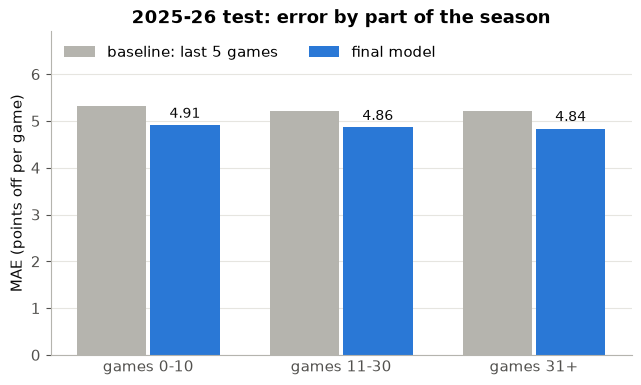

,games,avg_points,MAE_model,MAE_pts_l5,model_better_by
part of season,,,,,
games 0-10,3505,12.90,4.91,5.32,0.41
games 11-30,6315,12.85,4.86,5.22,0.36
games 31+,10012,12.83,4.84,5.22,0.38


In [31]:
t = breakdown("part of season")
bar_chart(t, "2025-26 test: error by part of the season", "10_test_mae_by_season_part.png")
t.round(2)

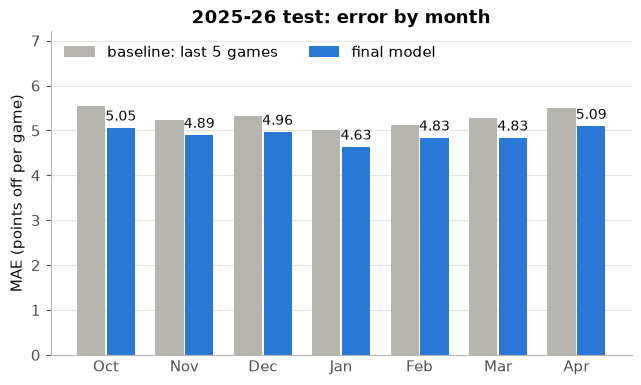

,games,avg_points,MAE_model,MAE_pts_l5,model_better_by
month,,,,,
Oct,1287,13.14,5.05,5.54,0.49
Nov,3459,13.26,4.89,5.24,0.35
Dec,3158,13.14,4.96,5.31,0.35
Jan,3830,12.61,4.63,5.01,0.38
Feb,2711,12.41,4.83,5.12,0.29
Mar,3920,12.61,4.83,5.28,0.45
Apr,1467,13.05,5.09,5.49,0.40


In [32]:
t = breakdown("month")
bar_chart(t, "2025-26 test: error by month", "11_test_mae_by_month.png")
t.round(2)

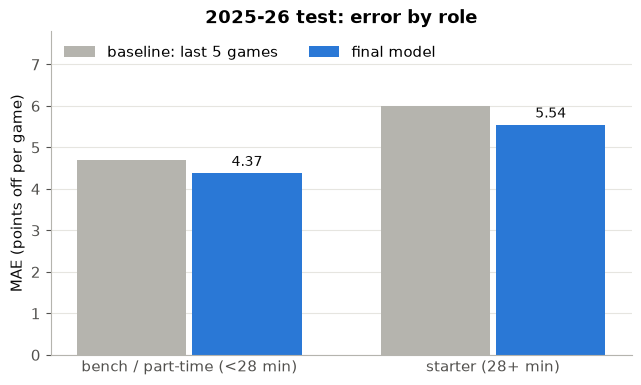

,games,avg_points,MAE_model,MAE_pts_l5,model_better_by
role,,,,,
bench / part-time (<28 min),11594,9.52,4.37,4.7,0.33
starter (28+ min),8238,17.54,5.54,6.0,0.46


In [33]:
t = breakdown("role")
bar_chart(t, "2025-26 test: error by role", "12_test_mae_by_role.png")
t.round(2)

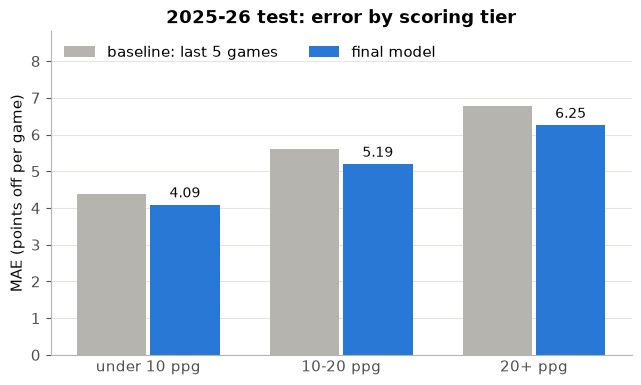

,games,avg_points,MAE_model,MAE_pts_l5,model_better_by
scoring tier,,,,,
under 10 ppg,8539,8.09,4.09,4.39,0.30
10-20 ppg,8634,14.19,5.19,5.60,0.41
20+ ppg,2659,23.80,6.25,6.77,0.52


In [34]:
t = breakdown("scoring tier")
bar_chart(t, "2025-26 test: error by scoring tier", "13_test_mae_by_tier.png")
t.round(2)

**Takeaway:**
- **The model beats the last-5 baseline in every group:** every part of the season, every month, both roles, all three scoring tiers. The gain is never under 0.29 points.
- **Season timing:** a player's first 10 games are only slightly harder (4.91 vs 4.84 later), and that's where the gain over the baseline is biggest (0.41). The blends with last season are doing their job. By month, **October and April are the hardest** (5.05, 5.09). October has new rosters and roles; April has resting stars, tanking teams and shuffled rotations. January is the easiest (4.63).
- **Stars are harder in points, easier in percent.** Starters are off by 5.54 vs 4.37 for bench players, and 20+ ppg scorers by 6.25 vs 4.09 for under-10 guys. But stars score much more: 6.25 on a 23.8-point average is about 26% off, while 4.09 on 8.1 is about 50%. The model's gain over the baseline is biggest for stars (0.52).

### Predicted vs actual

Like the class example's scatter plots, with `alpha=0.1` so dense areas show up darker. Each dot is one player-game. If the model were perfect, every dot would sit on the dashed diagonal.

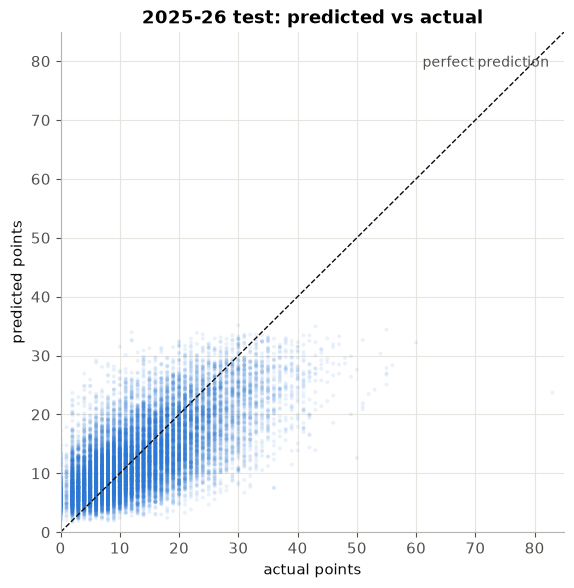

predictions range 1.7 to 35.1; actual range 0 to 83
within 3 points: 39%   within 5: 60%   off by 10+: 10%


In [35]:
fig, ax = plt.subplots(figsize=(6.5, 6.5))
ax.scatter(report["actual"], report["pred"], alpha=0.1, s=8, color=BLUE, edgecolors="none")
lim = max(report["actual"].max(), report["pred"].max()) + 2
ax.plot([0, lim], [0, lim], color=INK, linestyle="--", linewidth=1)
ax.text(lim * 0.97, lim * 0.93, "perfect prediction", ha="right", color=MUTED, fontsize=10)
ax.set_xlim(0, lim)
ax.set_ylim(0, lim)
ax.set_xlabel("actual points")
ax.set_ylabel("predicted points")
ax.set_title("2025-26 test: predicted vs actual")
fig.savefig(FIG_DIR / "14_test_pred_vs_actual.png")
plt.show()

print(f"predictions range {report['pred'].min():.1f} to {report['pred'].max():.1f}; "
      f"actual range {report['actual'].min()} to {report['actual'].max()}")
print(f"within 3 points: {(report['err_model'] <= 3).mean():.0%}   "
      f"within 5: {(report['err_model'] <= 5).mean():.0%}   "
      f"off by 10+: {(report['err_model'] >= 10).mean():.0%}")

**Takeaway:**
- The cloud follows the diagonal, but **predictions are squeezed together**: they range from 1.7 to 35.1 while actual games range from 0 to 83. The model predicts each player's *typical* night, and nobody's typical night is 50 points. The rare explosions (and the rare 2-point nights from good players) are the misses far from the line.
- That squeeze is by design: aiming at the typical night is what minimizes MAE. Predicting more 50-point games would mean being wrong on all the normal nights.
- **In plain numbers: 39% of predictions are within 3 points, 60% within 5, and 10% are off by 10 or more.**

## Step 3: save the models for the site

Two saved versions, same recipe (renamed `*_v1` on Nov 9, when version 2 at the end of this notebook became the site's model):
- **`models/final_model_v1.joblib`**: exactly the model scored above (trained through 2024-25). Kept so the reported test score can always be reproduced.
- **`models/deploy_model_v1.joblib`**: the same recipe **refit on 2018-19 through 2025-26**. Standard practice after testing: once the score is reported, retrain on all the data so the live 2026-27 predictions benefit from last season too. Its expected accuracy **is the test score above**. It's the same recipe with one more season of data, and there's no unseen season left to score it on (except the current one as it plays out).

Each file stores the model plus `FEATURES`, the blend weight and the training window, so the site always knows what columns to feed it. `src/predict.py` loads the deploy model (`models/deploy_model.joblib`, version 2 since Nov 9), and the site calls its `predict_points()`.

In [36]:
import datetime
import sklearn
import joblib

MODEL_DIR = ROOT / "models"
MODEL_DIR.mkdir(exist_ok=True)

def bundle(model, seasons, rows, note):
    return {"model": model, "version": "v1", "features": FEATURES, "blend_w": params["blend_w_hgb"],
            "train_seasons": seasons, "train_rows": rows,
            "description": params["best_model"] + ", clipped at 0",
            "hgb_params": params["hgb"], "huber_params": params["huber"],
            "cv_mae": float(cv_results_2a.loc[blend_name, "MAE_mean"]),
            "test_mae_2025_26": float(final_mae), "note": note,
            "sklearn_version": sklearn.__version__, "created": str(datetime.date.today())}

joblib.dump(bundle(final_model, "2018-19 to 2024-25", len(X_train),
                   "Scored once on the 2025-26 test set (test_mae_2025_26)."),
            MODEL_DIR / "final_model_v1.joblib")

# same recipe, one more season: everything 2018-19 through 2025-26
deploy_frame = df[df["SEASON"] >= "2018-19"].sort_values("GAME_DATE", kind="stable").reset_index(drop=True)
deploy_model = clone(final_model).fit(deploy_frame[FEATURES], deploy_frame["PTS"])
joblib.dump(bundle(deploy_model, "2018-19 to 2025-26", len(deploy_frame),
                   "Final recipe refit with 2025-26 included; expected accuracy = test_mae_2025_26."),
            MODEL_DIR / "deploy_model_v1.joblib")

for f in ["final_model_v1.joblib", "deploy_model_v1.joblib"]:
    print(f"{f}: {(MODEL_DIR / f).stat().st_size / 1e6:.1f} MB")
print(f"deploy model trained on {len(deploy_frame):,} games ({deploy_frame['SEASON'].min()} to {deploy_frame['SEASON'].max()})")

final_model_v1.joblib: 0.8 MB
deploy_model_v1.joblib: 0.8 MB
deploy model trained on 151,668 games (2018-19 to 2025-26)


In [37]:
# check: the saved version 1 deploy model on the current season's games so far
# (2026-27; not used for anything else). src/predict.py serves version 2 since Nov 9.
from predict import load_bundle, predict_points   # used in the version 2 section

live = pd.read_csv(ROOT / "data" / "processed" / "features.csv", parse_dates=["GAME_DATE"])
live = live[live["SEASON"] == "2026-27"].copy()
saved_deploy = joblib.load(MODEL_DIR / "deploy_model_v1.joblib")
live["predicted"] = saved_deploy["model"].predict(live[saved_deploy["features"]])

# and the saved final model reproduces the test score exactly
saved_final = joblib.load(MODEL_DIR / "final_model_v1.joblib")["model"]
print(f"saved final_model test MAE: {mean_absolute_error(y_test, saved_final.predict(X_test)):.3f}")
print(f"2026-27 so far ({len(live):,} games through {live['GAME_DATE'].max().date()}): "
      f"deploy model MAE {mean_absolute_error(live['PTS'], live['predicted']):.3f}, "
      f"last-5 baseline {mean_absolute_error(live['PTS'], live['pts_l5']):.3f}")
live[["GAME_DATE", "PLAYER_NAME", "TEAM", "OPP", "pts_l5", "predicted", "PTS"]].tail(8).round({"pts_l5": 1, "predicted": 1})

saved final_model test MAE: 4.857
2026-27 so far (2,383 games through 2026-11-08): deploy model MAE 4.855, last-5 baseline 5.342


,GAME_DATE,PLAYER_NAME,TEAM,OPP,pts_l5,predicted,PTS
154043,2026-11-08,De'Andre Hunter,SAC,MIA,17.4,13.8,14
154044,2026-11-08,Precious Achiuwa,SAC,MIA,10.4,10.3,7
154045,2026-11-08,Davion Mitchell,MIA,SAC,14.6,13.5,17
154046,2026-11-08,Keegan Murray,SAC,MIA,7.0,9.6,10
154047,2026-11-08,Leaky Black,SAC,MIA,5.8,6.1,6
154048,2026-11-08,Pelle Larsson,MIA,SAC,12.8,11.0,11
154049,2026-11-08,Darius Acuff Jr.,SAC,MIA,28.2,26.5,32
154050,2026-11-08,Emanuel Sharp,SAC,MIA,4.6,5.2,5


**Takeaway:**
- **Both models are saved (0.8 MB each).** The saved `final_model_v1` reproduces the 4.857 test MAE exactly. (Since Nov 9 the site's `src/predict.py` loads version 2's `deploy_model`, saved at the end of this notebook.)
- **The deploy model on the live 2026-27 season so far:** 4.86 points off vs 5.34 for the last-5 baseline (2,383 games through Nov 8; it was 4.91 vs 5.49 on Nov 2). These games are brand new to the deploy model, so this is a fair early check. It's in line with the test set's October (5.05), which was the hardest month. Early in the season the gap over the baseline is biggest (0.49 here), because last-5 averages are noisiest then.
- This is just a report. The model stays as is; we'll re-check it as the season goes on.

## Final results

- **On a season it never saw (2025-26, 19,832 games), the model is off by 4.86 points per game**, vs 5.24 for "same as his last 5 games". That's **7% better**, the same gap cross-validation promised (4.90 vs 5.28).
- **Final model: a 60/40 blend of a tuned gradient-boosting model and a tuned Huber regression**, trained on 8 seasons (2018-19 to 2024-25), chosen entirely on cross-validation before the test set was opened.
- **It beats the baseline everywhere:** every month, early and late in the season, starters and bench, low and high scorers. It helps most for stars and early-season games.
- **What it can't do: explosions.** Predictions top out around 35 points because the model aims at a player's typical night. 60% of predictions land within 5 points; 10% miss by 10+, mostly surprise big nights, injuries and blowouts.
- **It's live-ready:** retrained through 2025-26 for the site, and on 2026-27 so far it's off by 4.86 vs 5.34 for the baseline (through Nov 8).
- **Version 2** (below) adds the shot volume of players who are out. It replaced this model on the site on Nov 9; this section's 4.857 stays the pre-committed test result.

---
# Version 2: who's out, by shots not just minutes

*Added Nov 9.*

**The idea.** Version 1 knows *how many minutes* of his teammates are missing tonight (`team_missing_min`), but not *whose* minutes. To the model, Austin Reaves sitting out (about 35 minutes and 18 shots a game) looks exactly like a 35-minute defensive role player who takes 6 shots sitting out. Those aren't the same: when a scorer sits, his shots have to go to somebody.

**Two new features** (`src/build_features.py`, same rotation rule and same leak rules as `team_missing_min`):
- `team_missing_tsa`: total usual shot attempts of his team's rotation players who are out tonight. "Usual shots" = that player's season average of true shooting attempts (TSA = FGA + 0.44 x FTA) through his last game, computed exactly like "usual minutes".
- `opp_missing_tsa`: the same for the opponent.

**Checks before modeling** (`python src/check_features.py`): `team_missing_min` is unchanged on every row of the rebuilt `features.csv`, the leak test still passes (all 35 features identical when every game after 2025-01-15 is deleted), and a by-hand recomputation of the four "players out" numbers for one game (Tatum, Feb 12 2025: Jaylen Brown + Jrue Holiday out = 65.6 minutes, 30.6 shots) matches.

**The plan:** same date-safe folds, same tuned settings from `best_params.json` (no re-tuning), same 60/40 blend. Version 2 is kept only if it beats version 1 in **4 or more of the 5 folds** (the same rule as every other decision in part 2a).

Everything above this section is version 1 and still uses its 33 features (`FEATURES` = `FEATURES_V1`), so re-running the notebook reproduces version 1 exactly.

In [38]:
from build_features import FEATURES as FEATURES_V2   # version 1's 33 + the 2 shot-volume features
NEW_V2 = ["team_missing_tsa", "opp_missing_tsa"]
assert FEATURES_V2 == FEATURES + NEW_V2              # FEATURES (above) = version 1's 33

preprocessing_v2 = ColumnTransformer([
    ("num", make_pipeline(SimpleImputer(strategy="median", add_indicator=True), StandardScaler()),
     FEATURES_V2),
])
params = json.loads((RESULTS_DIR / "best_params.json").read_text())   # same tuned settings as version 1
huber_v2 = Pipeline([("preprocessing", preprocessing_v2), ("huber", HuberRegressor(**params["huber"]))])
hgb_v2 = Pipeline([("preprocessing", preprocessing_v2),
                   ("hgb", HistGradientBoostingRegressor(**params["hgb"]))])
W = params["blend_w_hgb"]

X_train_v2, y_train_v2 = train_frame[FEATURES_V2], train_frame["PTS"]
oof_v2 = {"Huber (tuned)": oof_predict(huber_v2, X_train_v2, y_train_v2),
          "HistGB (tuned)": oof_predict(hgb_v2, X_train_v2, y_train_v2)}
oof_v2[blend_name] = [W * h + (1 - W) * u
                      for h, u in zip(oof_v2["HistGB (tuned)"], oof_v2["Huber (tuned)"])]

# per fold: version 1 (Step 3's out-of-fold predictions, same folds) vs version 2
fold_v2 = pd.DataFrame({"v1 blend": per_fold(oof[blend_name], y=y_train_v2)["MAE"],
                        "v2 blend": per_fold(oof_v2[blend_name], y=y_train_v2)["MAE"]})
fold_v2["v2 better by"] = fold_v2["v1 blend"] - fold_v2["v2 blend"]
fold_v2.loc["mean"] = fold_v2.mean()
display(fold_v2.round(4))

rows = []
for name in [blend_name, "HistGB (tuned)", "Huber (tuned)"]:
    v1, v2 = per_fold(oof[name], y=y_train_v2), per_fold(oof_v2[name], y=y_train_v2)
    rows.append({"model": name, "v1 CV MAE": v1["MAE"].mean(), "v2 CV MAE": v2["MAE"].mean(),
                 "v2 better by": v1["MAE"].mean() - v2["MAE"].mean(),
                 "v1 RMSE": v1["RMSE"].mean(), "v2 RMSE": v2["RMSE"].mean(),
                 "v2 folds won": int((v2["MAE"].to_numpy() < v1["MAE"].to_numpy()).sum())})
cv_v2 = pd.DataFrame(rows).set_index("model")
cv_v2.to_csv(RESULTS_DIR / "cv_results_v2.csv")

V2_FOLDS_WON = int(cv_v2.loc[blend_name, "v2 folds won"])
KEEP_V2 = V2_FOLDS_WON >= 4
print(f"version 2 blend beats version 1 in {V2_FOLDS_WON} of 5 folds -> "
      f"{'KEEP version 2' if KEEP_V2 else 'stay with version 1'}")
cv_v2.round(4)

,v1 blend,v2 blend,v2 better by
fold1,4.9147,4.9068,0.0079
fold2,4.9137,4.9001,0.0136
fold3,4.9257,4.9210,0.0047
fold4,4.8644,4.8607,0.0038
fold5,4.8764,4.8743,0.0021
mean,4.8990,4.8926,0.0064


version 2 blend beats version 1 in 5 of 5 folds -> KEEP version 2


,v1 CV MAE,v2 CV MAE,v2 better by,v1 RMSE,v2 RMSE,v2 folds won
model,,,,,,
Blend (0.6 HistGB + 0.4 Huber),4.8990,4.8926,0.0064,6.3292,6.3210,5
HistGB (tuned),4.9034,4.8987,0.0046,6.3366,6.3310,5
Huber (tuned),4.9087,4.9019,0.0067,6.3378,6.3275,4


**Takeaway:**
- **Version 2 wins in every fold.** The blend goes from 4.899 to 4.893 points off per game (0.006 better). It's a small gain on average because most nights nobody important is out, but it's consistent: 5 of 5 folds, and bigger than the ~0.005 fold-to-fold noise. RMSE improves too (6.329 to 6.321).
- Both halves of the blend improve on their own (HistGB 5 of 5 folds, Huber 4 of 5), so it isn't a fluke of one model.
- Nothing else changed: same rows, same folds, same tuned settings, same 60/40 weights. The only difference is the two new columns.

### The Reaves example: why "whose minutes" matters

Take Luka Doncic's latest game in the data where nobody on the Lakers was out, and ask both models what happens if a 35-minute teammate sits. Version 1 can only add 35 missing minutes. Version 2 also adds that player's usual shots: Reaves' 2025-26 average (about 18) or 6 for a low-usage role player who plays the same minutes.

Both models here are trained on all of 2018-19 to 2024-25 (version 1 is `final_model` from part 2b; version 2 is the same recipe with the two extra columns). This is a what-if on one input row, not a score, so it doesn't touch the test set.

In [39]:
final_model_v2 = BlendRegressor(hgb=hgb_v2, huber=huber_v2, w=W).fit(X_train_v2, y_train_v2)

raw_2526 = pd.read_csv(ROOT / "data" / "raw" / "player_logs_2025-26.csv")
reaves = raw_2526[raw_2526["PLAYER_NAME"] == "Austin Reaves"]
reaves_min = reaves["MIN"].mean()
reaves_tsa = (reaves["FGA"] + 0.44 * reaves["FTA"]).mean()
LOW_USAGE_TSA = 6
print(f"Reaves 2025-26: {reaves_min:.1f} min, {reaves_tsa:.1f} shot attempts (TSA) a game")

all_rows = pd.read_csv(ROOT / "data" / "processed" / "features.csv", parse_dates=["GAME_DATE"])
# a fixed example game (his latest with no Laker out when this section was written), so the
# numbers don't drift when the data is refreshed
EXAMPLE_DATE = "2026-11-06"
luka = all_rows[all_rows["PLAYER_NAME"].str.startswith("Luka Don") & (all_rows["GAME_DATE"] == EXAMPLE_DATE)]
assert len(luka) == 1 and luka["team_missing_min"].iloc[0] == 0
print(f"example row: Luka, {EXAMPLE_DATE} vs {luka['OPP'].iloc[0]} (nobody out)")

def with_out(row, minutes, shots):
    x = row.copy()
    x["team_missing_min"] += minutes
    x["team_missing_tsa"] += shots
    return x

scenarios = {"everyone playing": with_out(luka, 0, 0),
             f"Reaves out ({reaves_min:.0f} min, {reaves_tsa:.0f} shots)": with_out(luka, reaves_min, reaves_tsa),
             f"{reaves_min:.0f}-min role player out ({LOW_USAGE_TSA} shots)": with_out(luka, reaves_min, LOW_USAGE_TSA)}
reaves_table = pd.DataFrame({
    "version 1": {k: final_model.predict(x[FEATURES])[0] for k, x in scenarios.items()},
    "version 2": {k: final_model_v2.predict(x[FEATURES_V2])[0] for k, x in scenarios.items()},
})
base = reaves_table.iloc[0]
reaves_bump = (reaves_table - base).iloc[1:].add_prefix("bump, ")
# saved for the site's Model Performance page (src/build_model_stats.py)
pd.concat([reaves_table, reaves_bump], axis=1).assign(
    teammate_min=[0, reaves_min, reaves_min], teammate_tsa=[0, reaves_tsa, LOW_USAGE_TSA],
    example=f"Luka Doncic, {EXAMPLE_DATE} vs {luka['OPP'].iloc[0]}",
).rename_axis("scenario").to_csv(RESULTS_DIR / "v2_reaves_example.csv")
display(reaves_table.round(2))
reaves_bump.round(2)

Reaves 2025-26: 34.6 min, 18.1 shot attempts (TSA) a game
example row: Luka, 2026-11-06 vs POR (nobody out)


,version 1,version 2
everyone playing,32.71,32.59
"Reaves out (35 min, 18 shots)",33.51,33.89
35-min role player out (6 shots),33.51,32.94


,"bump, version 1","bump, version 2"
"Reaves out (35 min, 18 shots)",0.8,1.30
35-min role player out (6 shots),0.8,0.35


**Takeaway:** Version 1 gives Luka the **same bump no matter who sits** (+0.8), because all it sees is "35 minutes missing". Version 2 gives a **bigger bump when the missing player is a scorer**: +1.3 for Reaves, whose 18 shots a game have to go somewhere (and Luka takes a lot of them), vs only +0.35 for a 6-shot role player playing the same minutes. That matches basketball intuition, and it's what the site's "who's out" switches now show.

(The search script in `results/search/v2_experiments/luka.py` got +1.19 / +0.25 on an earlier example row; the exact numbers depend on which of Luka's games is used as the starting point, the pattern doesn't.)

### What else we tried for "who's out" (and why it didn't make the cut)

Same folds, same settings, same rule. Run outside the notebook (scripts in `results/search/v2_experiments/`). Lower is better; differences under ~0.005 are noise.

| Tried | CV MAE | Folds won | Kept? |
|---|---|---|---|
| Version 1 (33 features) | 4.9000 | | baseline |
| **+ missing teammates' shots (version 2)** | **4.8923** | **5 of 5 vs version 1** | **yes** |
| + missing teammates' points instead | 4.8927 | 5 of 5 vs version 1 | no: same idea as shots, slightly worse |
| + biggest shooter out (largest single missing TSA) | 4.8948 | 5 of 5 vs version 1 | no: worse than total shots |
| + shots, points and biggest shooter together | 4.8903 | 4 of 5 vs version 2 | no: 0.002 better = noise, for 3 extra columns |
| version 2 + opponent's missing blocks | 4.8920 | 3 of 5 vs version 2 | no |
| version 2 + opponent's missing blocks + steals | 4.8921 | 4 of 5 vs version 2 | no: 0.0002 = noise |
| version 2 + opponent's missing defensive rebounds | 4.8918 | 3 of 5 vs version 2 | no |
| version 2 + opponent's missing plus-minus | 4.8924 | 2 of 5 vs version 2 | no |
| version 2 + opponent's missing "defensive rating without vs with him" | 4.8918 | 4 of 5 vs version 2 | no: 0.0005 = noise |

(The version 1 / version 2 numbers here, 4.9000 / 4.8923, come from the search scripts and differ from the table above in the 4th decimal: HistGB's random feature sampling depends on row order, and the scripts built the table with a different row order. Same conclusion.)

**Why the missing-defender features failed:** box scores and game-level with/without splits can't isolate defense. Blocks, steals and rebounds miss most of what a defender does (contesting, rotating, keeping people out of the paint), and a team's defense with vs without a player is mixed up with who else played, the schedule and a small number of games. So a missing star defender (Wembanyama, for example) is a known blind spot of this model.

### Test set: version 2 on 2025-26 (a second look)

**Read this before the numbers.** The 2025-26 test set was already used once, for version 1 (4.857, part 2b). Version 2 was built afterwards, and some of the questions behind it looked at 2025-26 games (the Reaves usage numbers and the Wembanyama with/without numbers come from that season). So this is a **second look** at the test set, not a clean test:
- **Version 1's 4.857 stays the pre-committed result.** It was the only model scored before anyone looked.
- **The clean check for version 2 is the live 2026-27 season**, games that didn't exist when version 2 was built (tracked on the site's Model Performance page).

Version 2 was chosen on cross-validation alone (above), so the score below can't change any decision. It's a report.

In [40]:
X_test_v2 = test_set[FEATURES_V2]
test_preds_v2 = {
    blend_name: final_model_v2.predict(X_test_v2),
    "HistGB (tuned)": final_model_v2.hgb_.predict(X_test_v2),
    "Huber (tuned)": final_model_v2.huber_.predict(X_test_v2),
}
v2_rows = pd.DataFrame({
    f"v2 {name}": {"test_MAE": mean_absolute_error(y_test, p),
                   "test_RMSE": root_mean_squared_error(y_test, p),
                   "test_R2": r2_score(y_test, p),
                   "CV_MAE": cv_v2.loc[name, "v2 CV MAE"]}
    for name, p in test_preds_v2.items()
}).T
v2_rows["test_minus_CV"] = v2_rows["test_MAE"] - v2_rows["CV_MAE"]
v2_rows["test_MAE_vs_pts_l5"] = v2_rows["test_MAE"] - test_results.loc["baseline: pts_l5", "test_MAE"]
v2_rows["version"] = "v2"

v1_rows = test_results.drop(columns="version", errors="ignore").copy()   # part 2b's table
v1_rows["version"] = np.where(v1_rows.index.str.startswith("baseline"), "baseline", "v1")
test_results_all = pd.concat([v2_rows, v1_rows]).sort_values("test_MAE")
test_results_all.index.name = "approach"
test_results_all = test_results_all[["version"] + [c for c in test_results_all.columns if c != "version"]]
test_results_all.to_csv(RESULTS_DIR / "test_results.csv")

final_mae_v2 = test_results_all.loc[f"v2 {blend_name}", "test_MAE"]
print(f"2025-26 test set ({len(y_test):,} games), blend: version 1 {final_mae:.3f} (pre-committed) | "
      f"version 2 {final_mae_v2:.3f} (second look)")
test_results_all.round(3)

2025-26 test set (19,832 games), blend: version 1 4.857 (pre-committed) | version 2 4.848 (second look)


,version,test_MAE,test_RMSE,test_R2,CV_MAE,test_minus_CV,test_MAE_vs_pts_l5
approach,,,,,,,
v2 Blend (0.6 HistGB + 0.4 Huber),v2,4.848,6.264,0.469,4.893,-0.044,-0.389
v2 HistGB (tuned),v2,4.853,6.274,0.467,4.899,-0.045,-0.383
Blend (0.6 HistGB + 0.4 Huber),v1,4.857,6.278,0.466,4.899,-0.042,-0.380
v2 Huber (tuned),v2,4.858,6.271,0.467,4.902,-0.044,-0.379
HistGB (tuned),v1,4.862,6.285,0.465,4.903,-0.042,-0.375
Huber (tuned),v1,4.866,6.287,0.465,4.909,-0.043,-0.371
Ridge (tuned),v1,4.902,6.283,0.465,4.937,-0.036,-0.335
baseline: pts_blend,baseline,5.051,6.538,0.421,5.080,-0.028,-0.186
baseline: pts_season,baseline,5.061,6.560,0.417,5.092,-0.031,-0.176


In [41]:
# where does version 2 differ? test games grouped by how many teammate shots were missing
pred_v1, pred_v2 = final_predictions, test_preds_v2[blend_name]
by_out = pd.DataFrame({"actual": y_test.to_numpy(),
                       "err_v1": np.abs(y_test.to_numpy() - pred_v1),
                       "err_v2": np.abs(y_test.to_numpy() - pred_v2),
                       "shots out": pd.cut(test_set["team_missing_tsa"], [-1, 0, 15, 30, 1000],
                                           labels=["nobody out", "under 15 shots", "15-30 shots", "30+ shots"])})
t = by_out.groupby("shots out", observed=True).agg(games=("actual", "size"), MAE_v1=("err_v1", "mean"),
                                                   MAE_v2=("err_v2", "mean"))
t["v2 better by"] = t["MAE_v1"] - t["MAE_v2"]
t.to_csv(RESULTS_DIR / "v2_test_by_shots_out.csv")
t.round(3)

,games,MAE_v1,MAE_v2,v2 better by
shots out,,,,
nobody out,3040,4.826,4.826,-0.001
under 15 shots,4978,4.761,4.746,0.015
15-30 shots,6282,4.861,4.845,0.016
30+ shots,5532,4.955,4.956,-0.001


**Takeaway:**
- **Version 2: 4.848 vs version 1's 4.857** on 2025-26 (0.009 better; CV said 0.006). Same ranking as CV, and both versions were ~0.04 better on 2025-26 than in CV, like every model in part 2b (an easier season).
- **Where the gain comes from:** nights with some teammate shots missing (under 30), about 0.015 better. With nobody out the two versions see the same inputs, so they tie, as they should. With 30+ shots missing (usually several players out) there's no gain: version 1's missing minutes already flag a big absence, and spreading that many shots across the remaining players is hard to predict.
- **Reminder:** this is a second look. Version 1's 4.857 is the pre-committed number; version 2's clean check is the live 2026-27 season (next cell).

### Save version 2 as the site's model

- `models/final_model.joblib` / `models/deploy_model.joblib` are now **version 2** (deploy = same recipe refit on 2018-19 through 2025-26, like part 2b).
- Version 1 stays in `models/final_model_v1.joblib` / `models/deploy_model_v1.joblib` (saved in part 2b's Step 3), so its 4.857 can always be reproduced.

In [42]:
assert KEEP_V2, "version 2 didn't win 4+ folds; don't replace version 1"

def bundle_v2(model, seasons, rows, note):
    return {"model": model, "version": "v2", "features": FEATURES_V2, "blend_w": W,
            "train_seasons": seasons, "train_rows": rows,
            "description": params["best_model"] + ", clipped at 0 (version 2: + teammates' missing shots)",
            "hgb_params": params["hgb"], "huber_params": params["huber"],
            "cv_mae": float(cv_v2.loc[blend_name, "v2 CV MAE"]),
            "test_mae_2025_26": float(final_mae_v2), "test_mae_v1_precommitted": float(final_mae),
            "note": note, "sklearn_version": sklearn.__version__, "created": str(datetime.date.today())}

joblib.dump(bundle_v2(final_model_v2, "2018-19 to 2024-25", len(X_train_v2),
                      "Version 2. Second look at the 2025-26 test set (version 1's 4.857 is the pre-committed result)."),
            MODEL_DIR / "final_model.joblib")
deploy_model_v2 = clone(final_model_v2).fit(deploy_frame[FEATURES_V2], deploy_frame["PTS"])
joblib.dump(bundle_v2(deploy_model_v2, "2018-19 to 2025-26", len(deploy_frame),
                      "Version 2 refit with 2025-26 included. Clean check = the live 2026-27 season."),
            MODEL_DIR / "deploy_model.joblib")

params["version_2"] = {
    "features": "FEATURES in build_features.py (35) = version 1's 33 + team_missing_tsa, opp_missing_tsa",
    "same_settings_as_version_1": True,
    "cv_mae": {"blend": float(cv_v2.loc[blend_name, "v2 CV MAE"]),
               "hgb": float(cv_v2.loc["HistGB (tuned)", "v2 CV MAE"]),
               "huber": float(cv_v2.loc["Huber (tuned)", "v2 CV MAE"])},
    "cv_mae_version_1_blend": float(cv_v2.loc[blend_name, "v1 CV MAE"]),
    "folds_won_vs_version_1": V2_FOLDS_WON,
    "test_mae_2025_26": float(final_mae_v2),
    "test_note": "second look at 2025-26; version 1's test MAE is the pre-committed result",
}
params["current_version"] = "v2"
(RESULTS_DIR / "best_params.json").write_text(json.dumps(params, indent=2))

# check: the site's loader (src/predict.py) now serves version 2, and the live 2026-27 season so far
load_bundle.cache_clear()
live = all_rows[all_rows["SEASON"] == "2026-27"].copy()
assert np.allclose(predict_points(live), deploy_model_v2.predict(live[FEATURES_V2]))
deploy_v1 = joblib.load(MODEL_DIR / "deploy_model_v1.joblib")["model"]
print(f"2026-27 so far ({len(live):,} games through {live['GAME_DATE'].max().date()}), MAE: "
      f"version 2 {mean_absolute_error(live['PTS'], predict_points(live)):.3f} | "
      f"version 1 {mean_absolute_error(live['PTS'], deploy_v1.predict(live[FEATURES])):.3f} | "
      f"last-5 baseline {mean_absolute_error(live['PTS'], live['pts_l5']):.3f}")
for f in ["final_model.joblib", "deploy_model.joblib", "final_model_v1.joblib", "deploy_model_v1.joblib"]:
    print(f"{f}: {(MODEL_DIR / f).stat().st_size / 1e6:.1f} MB")

2026-27 so far (2,383 games through 2026-11-08), MAE: version 2 4.853 | version 1 4.855 | last-5 baseline 5.342
final_model.joblib: 0.8 MB
deploy_model.joblib: 0.8 MB
final_model_v1.joblib: 0.8 MB
deploy_model_v1.joblib: 0.8 MB


## Key findings (version 2)

- **Whose minutes are missing matters, not just how many.** Adding the usual shot attempts of missing teammates (and opponents) beat version 1 in all 5 validation folds.
- **Small but consistent.** CV MAE goes from 4.899 to 4.893. Most nights nobody important sits, so the average moves a little; on nights when scorers are out, the predictions move the way they should (Reaves out: +1.3 for Luka vs +0.35 for a role player; version 1 said +0.8 for both).
- **Honest test reporting.** Version 1's 4.857 on 2025-26 stays the pre-committed result. Version 2's 4.848 on 2025-26 is a second look; the live 2026-27 season is its clean check (see the output above: early days, the two versions are within a few thousandths).
- **Missing defenders are a known blind spot.** Blocks, steals, rebounds, plus-minus and with/without defensive rating all failed to beat noise. Box scores can't isolate defense.